In [5]:
import torch 
print(torch.cuda.is_available)

<function is_available at 0x7fd91e4ecaf0>


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
times = torch.linspace(1.0, imm_model.schedule.tmin, steps=32, device=device)

In [6]:
import torch
import torchvision
from torchvision import transforms
import numpy as np
from scipy.linalg import sqrtm

# ────────────────────────────────────────────────────────────────
# 1) Inception feature extractor
# ────────────────────────────────────────────────────────────────
_inception = None
def get_inception_features(x: torch.Tensor, device: torch.device, batch_size: int = 64):
    """
    x: [N,3,H,W] in [0,1]
    returns: np.ndarray [N,2048]
    """
    global _inception
    if _inception is None:
        _inception = torchvision.models.inception_v3(pretrained=False, transform_input=False)
        _inception.Mixed_7c.register_forward_hook(lambda m, i, o: setattr(_inception, "_pool3", o))
        _inception.fc = torch.nn.Identity()
        # **load form the local checkpoint**
        ckpt = torch.load("./inception_pool3.pth", map_location=device)
         # remove the fc parameters from the checkpoint so they don’t mismatch
        ckpt.pop("fc.weight", None)
        ckpt.pop("fc.bias",   None)
        _inception.load_state_dict(ckpt, strict=False)
        _inception.eval().to(device)

    # preprocess to Inception’s expected input
    preprocess = transforms.Compose([
        transforms.Resize((299,299)),
        transforms.Normalize(mean=[0.485,0.456,0.406],
                             std =[0.229,0.224,0.225])
    ])

    feats = []
    with torch.no_grad():
        for i in range(0, x.shape[0], batch_size):
            batch = x[i : i+batch_size].to(device)
            batch = preprocess(batch)
            _ = _inception(batch)
            pool3 = _inception._pool3  # [B,2048, 8, 8]
            # global-average pool to [B,2048]
            f = torch.nn.functional.adaptive_avg_pool2d(pool3, (1,1)).view(batch.size(0), -1)
            feats.append(f.cpu().numpy())
    return np.concatenate(feats, axis=0)

# ────────────────────────────────────────────────────────────────
# 2) FID computation
# ────────────────────────────────────────────────────────────────
def compute_fid_from_tensors(
    real_images: torch.Tensor,
    fake_images: torch.Tensor,
    device: torch.device,
    batch_size: int = 64
) -> float:
    """
    real_images, fake_images: [N,3,H,W] in [0,1]
    returns: scalar FID
    """
    # 1) extract features
    real_feats = get_inception_features(real_images, device, batch_size)  # [N,2048]
    fake_feats = get_inception_features(fake_images, device, batch_size)

    # 2) compute mean & cov
    mu_r    = real_feats.mean(axis=0)
    mu_g    = fake_feats.mean(axis=0)
    sigma_r = np.cov(real_feats, rowvar=False)
    sigma_g = np.cov(fake_feats,  rowvar=False)

    # 3) sqrtm of cov product
    covmean = sqrtm(sigma_r.dot(sigma_g))
    if np.iscomplexobj(covmean):
        covmean = covmean.real

    # 4) frechet distance
    diff = mu_r - mu_g
    fid  = diff.dot(diff) + np.trace(sigma_r + sigma_g - 2*covmean)
    return float(np.clip(fid, 0, None))


# ────────────────────────────────────────────────────────────────
# 3) Sample 5 000 fakes and reals, compute FID
# ────────────────────────────────────────────────────────────────
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

n_vis = 10000
times = torch.linspace(1.0, imm_model.schedule.tmin, steps=32, device=device)

# 3.1) generate fake images
with torch.no_grad():
    gen_z   = imm_model.sample(n_vis, times)           # [5000, z_dim]
    #gen_z = torch.randn(100, z_dim, device=device) 
    fakes   = vae_model.decoder(gen_z).cpu().clamp(-1,1)
    fakes   = (fakes + 1) / 2                          # → [0,1]

# 3.2) grab 5000 real images
celeba_test = DataLoader(CelebA("./data/CelebA", split='test', download=False, transform = celeba_transform),
        batch_size = batch_size,
        shuffle = False,
        drop_last = False,    # ← drop any partial final batch
        num_workers = 0,     # reduce to 2 to avoid “too many workers” warning
        pin_memory = True
    )
reals = []
needed = n_vis
it = iter(celeba_test)
while needed > 0:
    imgs, _ = next(it)                                 # [batch,3,H,W] in [-1,1]
    reals.append(imgs.cpu().clamp(-1,1))
    needed -= imgs.size(0)
reals = torch.cat(reals, dim=0)[:n_vis]                # [5000,3,H,W]
reals = (reals + 1) / 2                                # → [0,1]

# 3.3) compute FID
fid_score = compute_fid_from_tensors(reals, fakes, device, batch_size=64)
print(f"FID (5 000 samples): {fid_score:.4f}")


/media/abid/4TB/Anaconda/envs/IMM/lib/python3.9/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/media/abid/4TB/Anaconda/envs/IMM/lib/python3.9/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)
/media/abid/4TB/Anaconda/envs/IMM/lib/python3.9/site-packages/torchvision/models/inception.py:43: FutureWarning: The default weight initialization of inception_v3 will be changed in future releases of torchvision. If you wish to keep the old behavior (which leads to long initialization times due to scipy/scipy#11299), please set init_weights=True.
  warnings.warn(
/tmp/ipykernel_86744/3080297155.py:22: FutureWarning: You are using `torch.load`

FID (5 000 samples): 44.4925


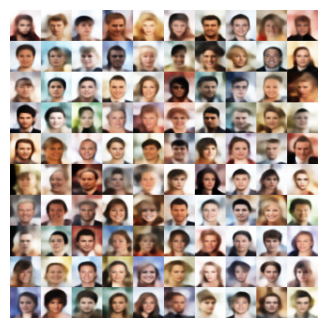

In [11]:
vae_model.eval()
imm_model.eval()
torch.set_grad_enabled(False)
device = torch.device("cuda" if (torch.cuda.is_available()) else "cpu")

num_gen = 100
times = torch.linspace(1.0, imm_model.schedule.tmin, steps=32)  # e.g. [1.0,0.857,…,0.0]
z_gen = imm_model.sample(num_gen, times)    # [100, z_dim]
#z_gen = torch.randn(100, z_dim, device=device)  # [100, z_dim] random noise
samples = vae_model.decoder(z_gen)          # [100,1,28,28]
 # ---- Denormalize from [-1,1] → [0,1] ----
samples = samples.cpu()
samples = samples * 0.5 + 0.5    # if you used Normalize(0.5,0.5) during training
samples = samples.clamp(0, 1)
samples_np = samples.permute(0,2,3,1).numpy()  # [100,28,28,1]
plt.figure(figsize=(4,4))
plt.imshow(convert_to_display(samples_np))
plt.axis("off")
plt.show()

In [7]:
import torch
print(torch.hub.get_dir())

/home/abid/.cache/torch/hub


In [8]:
import torch, torchvision
inception = torchvision.models.inception_v3(pretrained=True, transform_input=False)
torch.save(inception.state_dict(), "./inception_pool3.pth")

Files already downloaded and verified
Current CUDA device: 0 NVIDIA GeForce GTX TITAN X
[Epoch 1/80  Step 200]  Reconstruction=0.08201  MMD=0.09476 IMM=-0.00160
[Epoch 1/80  Step 400]  Reconstruction=0.06135  MMD=0.02354 IMM=-0.05760
[Epoch 1/80  Step 600]  Reconstruction=0.05400  MMD=0.00731 IMM=-0.04875
[Epoch 1/80  Step 800]  Reconstruction=0.05043  MMD=0.00438 IMM=-0.07549
[Epoch 1/80  Step 1000]  Reconstruction=0.04070  MMD=0.00274 IMM=-0.08227


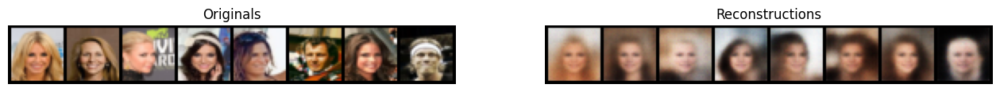

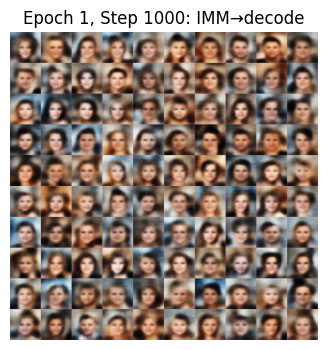

[Epoch 1/80  Step 1200]  Reconstruction=0.04145  MMD=0.00339 IMM=-0.03631
[Epoch 2/80  Step 1400]  Reconstruction=0.03831  MMD=0.00408 IMM=-0.03710
[Epoch 2/80  Step 1600]  Reconstruction=0.03705  MMD=0.00375 IMM=-0.05777
[Epoch 2/80  Step 1800]  Reconstruction=0.03414  MMD=0.00504 IMM=-0.01357
[Epoch 2/80  Step 2000]  Reconstruction=0.03525  MMD=0.00601 IMM=-0.04203


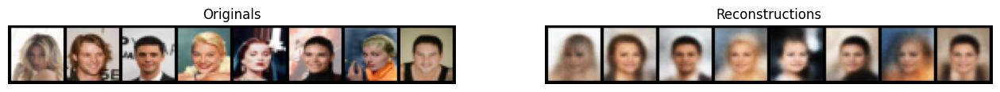

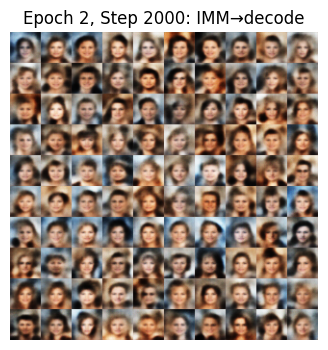

[Epoch 2/80  Step 2200]  Reconstruction=0.03684  MMD=0.00541 IMM=-0.01574
[Epoch 2/80  Step 2400]  Reconstruction=0.03113  MMD=0.00504 IMM=-0.11198
[Epoch 3/80  Step 2600]  Reconstruction=0.03079  MMD=0.00506 IMM=-0.05327
[Epoch 3/80  Step 2800]  Reconstruction=0.03035  MMD=0.00349 IMM=-0.07504
[Epoch 3/80  Step 3000]  Reconstruction=0.03458  MMD=0.00448 IMM=0.00412


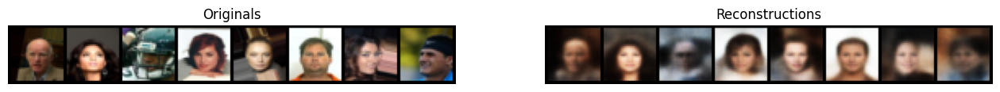

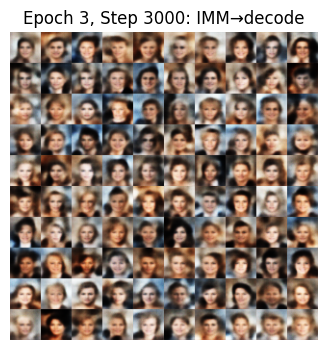

[Epoch 3/80  Step 3200]  Reconstruction=0.03008  MMD=0.00286 IMM=-0.10355
[Epoch 3/80  Step 3400]  Reconstruction=0.03391  MMD=0.00377 IMM=-0.05076
[Epoch 3/80  Step 3600]  Reconstruction=0.02900  MMD=0.00618 IMM=-0.01960
[Epoch 3/80  Step 3800]  Reconstruction=0.03002  MMD=0.00604 IMM=-0.07968
[Epoch 4/80  Step 4000]  Reconstruction=0.03057  MMD=0.00594 IMM=-0.06554


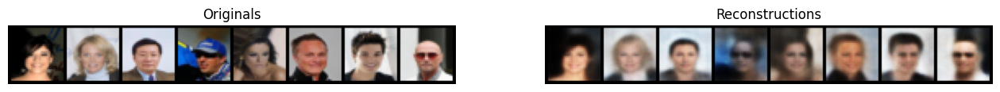

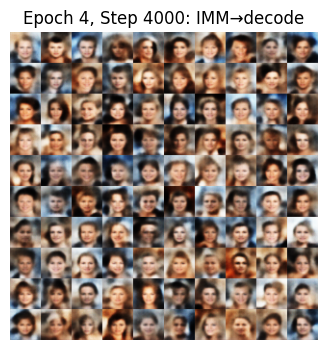

[Epoch 4/80  Step 4200]  Reconstruction=0.02918  MMD=0.00365 IMM=-0.02821
[Epoch 4/80  Step 4400]  Reconstruction=0.03075  MMD=0.00480 IMM=-0.04490
[Epoch 4/80  Step 4600]  Reconstruction=0.02764  MMD=0.00554 IMM=-0.03317
[Epoch 4/80  Step 4800]  Reconstruction=0.02864  MMD=0.00390 IMM=-0.17320
[Epoch 4/80  Step 5000]  Reconstruction=0.02886  MMD=0.00331 IMM=-0.06699


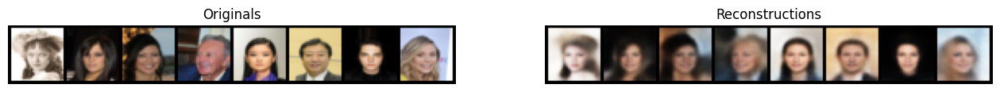

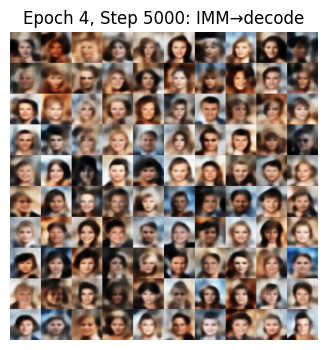

[Epoch 5/80  Step 5200]  Reconstruction=0.03059  MMD=0.00618 IMM=-0.04501
[Epoch 5/80  Step 5400]  Reconstruction=0.02686  MMD=0.00699 IMM=-0.03156
[Epoch 5/80  Step 5600]  Reconstruction=0.02813  MMD=0.00616 IMM=-0.09149
[Epoch 5/80  Step 5800]  Reconstruction=0.02791  MMD=0.00497 IMM=-0.02267
[Epoch 5/80  Step 6000]  Reconstruction=0.02926  MMD=0.00890 IMM=-0.06198


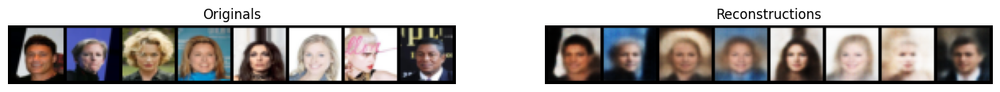

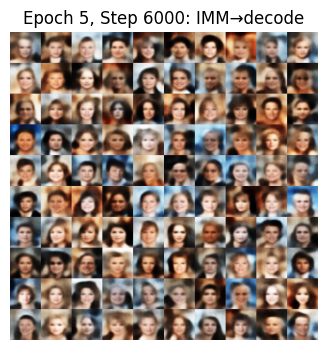

[Epoch 5/80  Step 6200]  Reconstruction=0.02737  MMD=0.00567 IMM=-0.03231
[Epoch 6/80  Step 6400]  Reconstruction=0.02649  MMD=0.00661 IMM=-0.05680
[Epoch 6/80  Step 6600]  Reconstruction=0.02576  MMD=0.01012 IMM=-0.05823
[Epoch 6/80  Step 6800]  Reconstruction=0.02728  MMD=0.00614 IMM=-0.01761
[Epoch 6/80  Step 7000]  Reconstruction=0.02727  MMD=0.01315 IMM=-0.03146


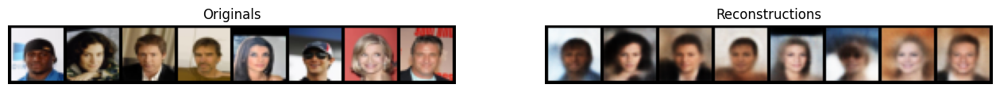

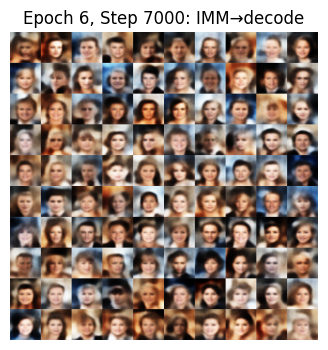

[Epoch 6/80  Step 7200]  Reconstruction=0.02605  MMD=0.01027 IMM=-0.05861
[Epoch 6/80  Step 7400]  Reconstruction=0.02584  MMD=0.00674 IMM=0.00471
[Epoch 6/80  Step 7600]  Reconstruction=0.02522  MMD=0.00729 IMM=-0.05949
[Epoch 7/80  Step 7800]  Reconstruction=0.02808  MMD=0.01055 IMM=-0.03166
[Epoch 7/80  Step 8000]  Reconstruction=0.02593  MMD=0.00714 IMM=-0.03259


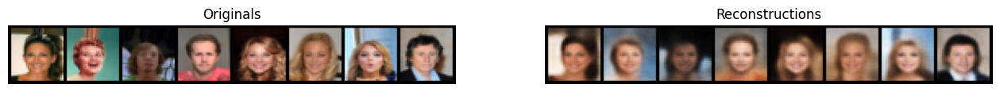

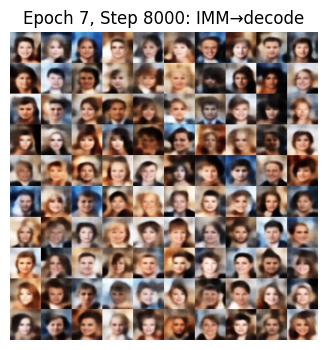

[Epoch 7/80  Step 8200]  Reconstruction=0.02459  MMD=0.00767 IMM=-0.05697
[Epoch 7/80  Step 8400]  Reconstruction=0.02503  MMD=0.00614 IMM=-0.05288
[Epoch 7/80  Step 8600]  Reconstruction=0.02326  MMD=0.00794 IMM=-0.04019
[Epoch 7/80  Step 8800]  Reconstruction=0.02822  MMD=0.00843 IMM=-0.10365
[Epoch 8/80  Step 9000]  Reconstruction=0.02329  MMD=0.00771 IMM=-0.03745


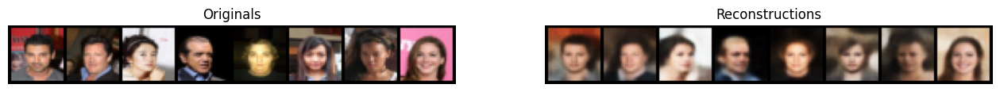

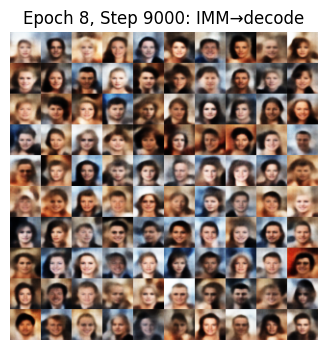

[Epoch 8/80  Step 9200]  Reconstruction=0.02393  MMD=0.00755 IMM=-0.03006
[Epoch 8/80  Step 9400]  Reconstruction=0.02410  MMD=0.00969 IMM=-0.02150
[Epoch 8/80  Step 9600]  Reconstruction=0.02277  MMD=0.01181 IMM=-0.02439
[Epoch 8/80  Step 9800]  Reconstruction=0.02444  MMD=0.00833 IMM=-0.05160
[Epoch 8/80  Step 10000]  Reconstruction=0.02335  MMD=0.00738 IMM=-0.02503


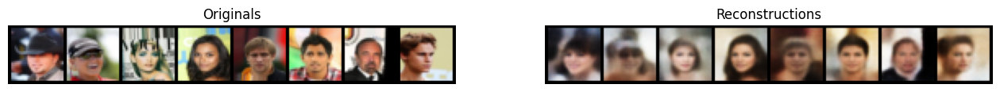

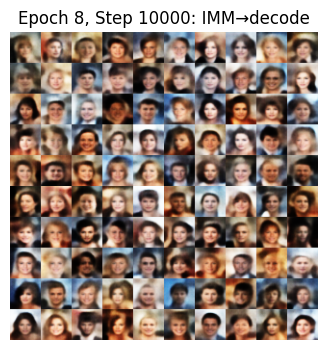

[Epoch 9/80  Step 10200]  Reconstruction=0.02430  MMD=0.00933 IMM=-0.04048
[Epoch 9/80  Step 10400]  Reconstruction=0.02308  MMD=0.01046 IMM=-0.05490
[Epoch 9/80  Step 10600]  Reconstruction=0.02345  MMD=0.02039 IMM=-0.01178
[Epoch 9/80  Step 10800]  Reconstruction=0.02235  MMD=0.00693 IMM=-0.05366
[Epoch 9/80  Step 11000]  Reconstruction=0.02446  MMD=0.00843 IMM=-0.05002


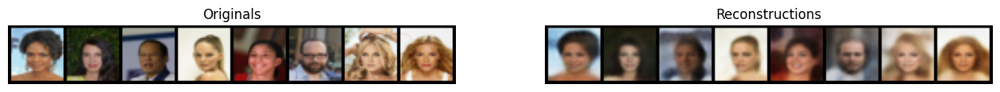

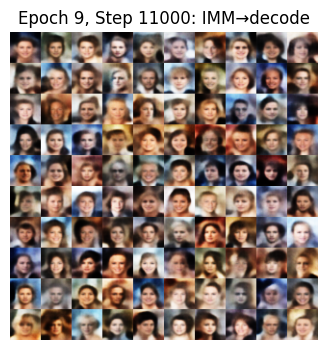

[Epoch 9/80  Step 11200]  Reconstruction=0.02438  MMD=0.00869 IMM=-0.04161
[Epoch 9/80  Step 11400]  Reconstruction=0.02367  MMD=0.01580 IMM=-0.04188
[Epoch 10/80  Step 11600]  Reconstruction=0.02273  MMD=0.02268 IMM=-0.02217
[Epoch 10/80  Step 11800]  Reconstruction=0.02371  MMD=0.00736 IMM=-0.01689
[Epoch 10/80  Step 12000]  Reconstruction=0.02488  MMD=0.00791 IMM=-0.05300


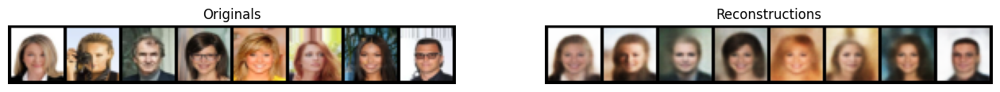

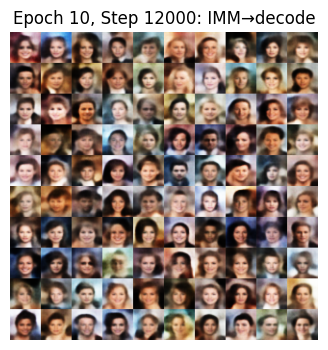

[Epoch 10/80  Step 12200]  Reconstruction=0.02252  MMD=0.00879 IMM=-0.03795
[Epoch 10/80  Step 12400]  Reconstruction=0.02395  MMD=0.01124 IMM=-0.04542
[Epoch 10/80  Step 12600]  Reconstruction=0.02387  MMD=0.01354 IMM=-0.04113
[Epoch 11/80  Step 12800]  Reconstruction=0.02318  MMD=0.00990 IMM=-0.02929
[Epoch 11/80  Step 13000]  Reconstruction=0.02463  MMD=0.01267 IMM=-0.02780


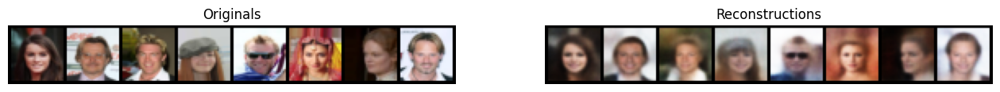

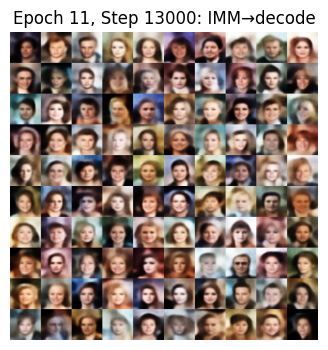

[Epoch 11/80  Step 13200]  Reconstruction=0.02353  MMD=0.01524 IMM=-0.01332
[Epoch 11/80  Step 13400]  Reconstruction=0.02345  MMD=0.01162 IMM=-0.02328
[Epoch 11/80  Step 13600]  Reconstruction=0.02237  MMD=0.01317 IMM=0.00297
[Epoch 11/80  Step 13800]  Reconstruction=0.02261  MMD=0.01985 IMM=-0.00917
[Epoch 12/80  Step 14000]  Reconstruction=0.02231  MMD=0.02017 IMM=-0.03852


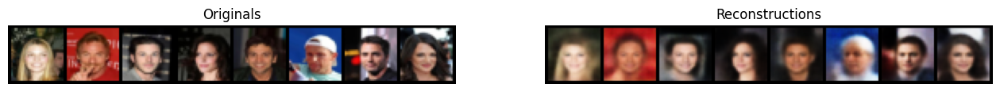

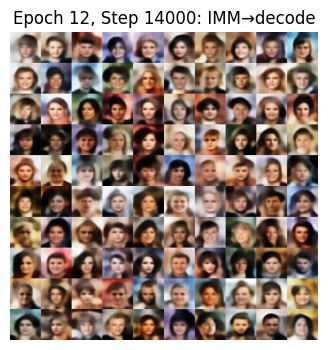

[Epoch 12/80  Step 14200]  Reconstruction=0.02362  MMD=0.01165 IMM=-0.05750
[Epoch 12/80  Step 14400]  Reconstruction=0.02500  MMD=0.01669 IMM=-0.04520
[Epoch 12/80  Step 14600]  Reconstruction=0.02176  MMD=0.01336 IMM=-0.00728
[Epoch 12/80  Step 14800]  Reconstruction=0.02307  MMD=0.03538 IMM=-0.03502
[Epoch 12/80  Step 15000]  Reconstruction=0.02268  MMD=0.00934 IMM=-0.00248


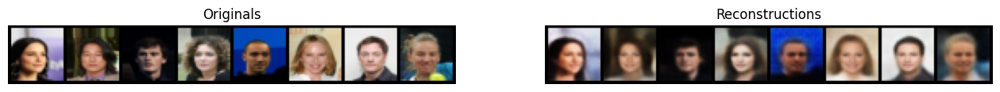

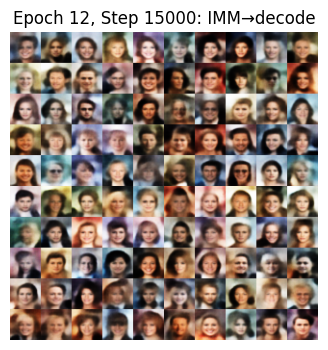

[Epoch 12/80  Step 15200]  Reconstruction=0.02240  MMD=0.01454 IMM=-0.06813
[Epoch 13/80  Step 15400]  Reconstruction=0.02266  MMD=0.01842 IMM=0.00170
[Epoch 13/80  Step 15600]  Reconstruction=0.02291  MMD=0.01380 IMM=-0.01621
[Epoch 13/80  Step 15800]  Reconstruction=0.02454  MMD=0.02534 IMM=-0.00425
[Epoch 13/80  Step 16000]  Reconstruction=0.02285  MMD=0.00969 IMM=-0.07388


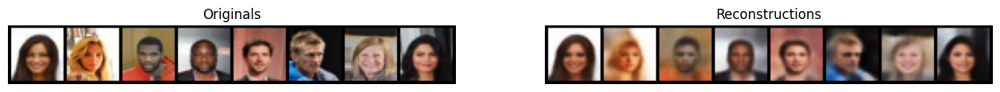

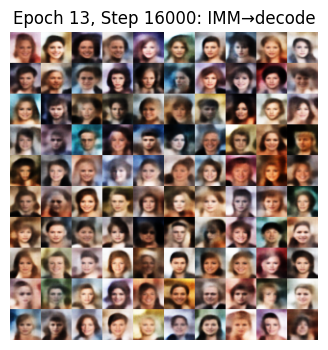

[Epoch 13/80  Step 16200]  Reconstruction=0.02346  MMD=0.01387 IMM=-0.01432
[Epoch 13/80  Step 16400]  Reconstruction=0.02175  MMD=0.01905 IMM=-0.02621
[Epoch 14/80  Step 16600]  Reconstruction=0.02302  MMD=0.01179 IMM=-0.02111
[Epoch 14/80  Step 16800]  Reconstruction=0.02112  MMD=0.03588 IMM=-0.06330
[Epoch 14/80  Step 17000]  Reconstruction=0.02266  MMD=0.02832 IMM=-0.06242


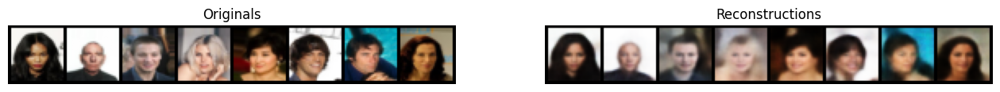

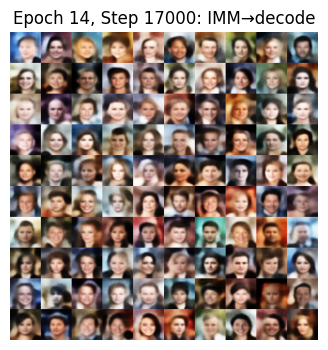

[Epoch 14/80  Step 17200]  Reconstruction=0.02382  MMD=0.01673 IMM=-0.03401
[Epoch 14/80  Step 17400]  Reconstruction=0.02334  MMD=0.02138 IMM=-0.02183
[Epoch 14/80  Step 17600]  Reconstruction=0.02263  MMD=0.01985 IMM=-0.02657
[Epoch 15/80  Step 17800]  Reconstruction=0.02348  MMD=0.01696 IMM=0.01017
[Epoch 15/80  Step 18000]  Reconstruction=0.02121  MMD=0.01385 IMM=-0.02507


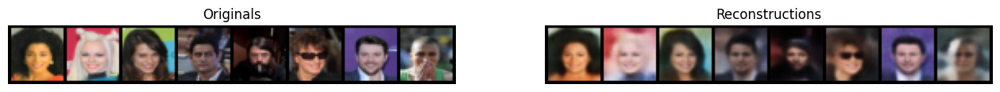

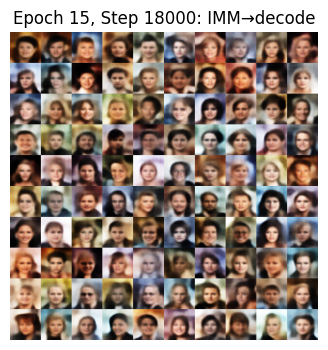

[Epoch 15/80  Step 18200]  Reconstruction=0.02155  MMD=0.01624 IMM=-0.00498
[Epoch 15/80  Step 18400]  Reconstruction=0.02228  MMD=0.01038 IMM=0.00348
[Epoch 15/80  Step 18600]  Reconstruction=0.02112  MMD=0.02224 IMM=-0.04798
[Epoch 15/80  Step 18800]  Reconstruction=0.02266  MMD=0.01994 IMM=-0.01205
[Epoch 15/80  Step 19000]  Reconstruction=0.02312  MMD=0.01834 IMM=0.00502


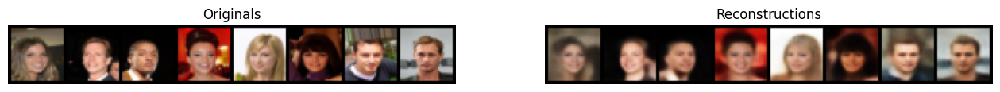

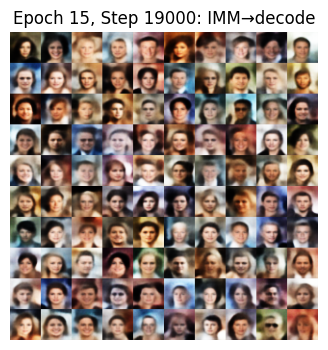

[Epoch 16/80  Step 19200]  Reconstruction=0.02070  MMD=0.04751 IMM=0.01393
[Epoch 16/80  Step 19400]  Reconstruction=0.02265  MMD=0.02466 IMM=-0.00760
[Epoch 16/80  Step 19600]  Reconstruction=0.02146  MMD=0.02238 IMM=-0.03347
[Epoch 16/80  Step 19800]  Reconstruction=0.02153  MMD=0.02139 IMM=-0.03079
[Epoch 16/80  Step 20000]  Reconstruction=0.02150  MMD=0.02006 IMM=-0.02913


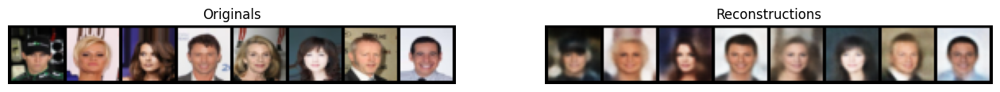

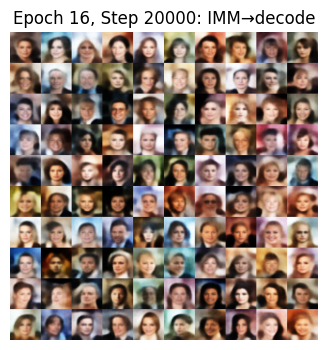

[Epoch 16/80  Step 20200]  Reconstruction=0.02277  MMD=0.02641 IMM=-0.00646
[Epoch 17/80  Step 20400]  Reconstruction=0.02195  MMD=0.07986 IMM=-0.01777
[Epoch 17/80  Step 20600]  Reconstruction=0.02161  MMD=0.01946 IMM=0.00230
[Epoch 17/80  Step 20800]  Reconstruction=0.02241  MMD=0.01800 IMM=-0.01604
[Epoch 17/80  Step 21000]  Reconstruction=0.02227  MMD=0.02110 IMM=-0.01986


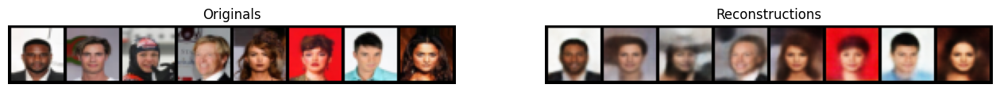

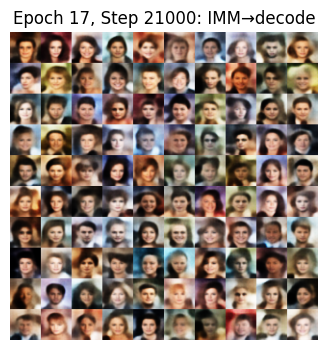

[Epoch 17/80  Step 21200]  Reconstruction=0.02206  MMD=0.01729 IMM=-0.00781
[Epoch 17/80  Step 21400]  Reconstruction=0.02188  MMD=0.03278 IMM=-0.01377
[Epoch 17/80  Step 21600]  Reconstruction=0.02160  MMD=0.05189 IMM=0.00679
[Epoch 18/80  Step 21800]  Reconstruction=0.02253  MMD=0.03992 IMM=-0.03443
[Epoch 18/80  Step 22000]  Reconstruction=0.02116  MMD=0.01647 IMM=0.00764


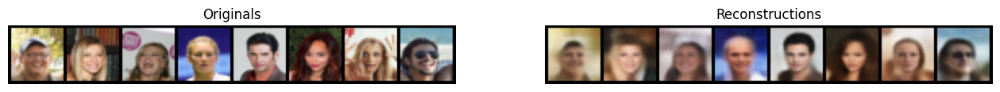

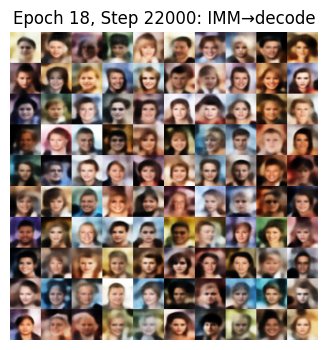

[Epoch 18/80  Step 22200]  Reconstruction=0.02046  MMD=0.02274 IMM=-0.01703
[Epoch 18/80  Step 22400]  Reconstruction=0.02259  MMD=0.02567 IMM=-0.00781
[Epoch 18/80  Step 22600]  Reconstruction=0.02063  MMD=0.04344 IMM=-0.00717
[Epoch 18/80  Step 22800]  Reconstruction=0.02201  MMD=0.01454 IMM=-0.02522
[Epoch 19/80  Step 23000]  Reconstruction=0.02242  MMD=0.02263 IMM=-0.03238


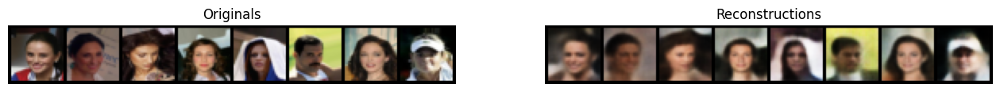

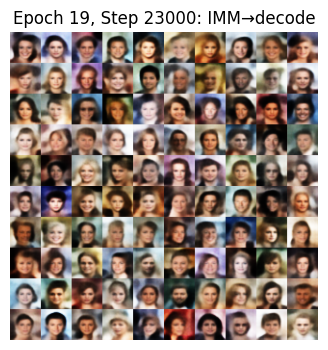

[Epoch 19/80  Step 23200]  Reconstruction=0.02211  MMD=0.02782 IMM=-0.04865
[Epoch 19/80  Step 23400]  Reconstruction=0.02021  MMD=0.02310 IMM=-0.01215
[Epoch 19/80  Step 23600]  Reconstruction=0.02202  MMD=0.01862 IMM=-0.00264
[Epoch 19/80  Step 23800]  Reconstruction=0.02002  MMD=0.04322 IMM=-0.04041
[Epoch 19/80  Step 24000]  Reconstruction=0.02303  MMD=0.01695 IMM=-0.02483


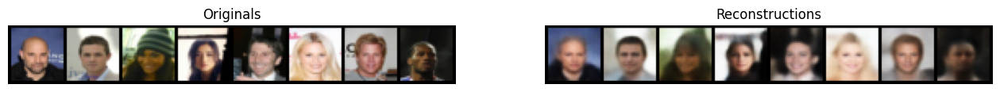

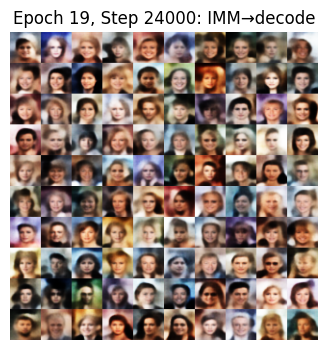

[Epoch 20/80  Step 24200]  Reconstruction=0.02044  MMD=0.01943 IMM=0.00684
[Epoch 20/80  Step 24400]  Reconstruction=0.02250  MMD=0.01728 IMM=-0.03703
[Epoch 20/80  Step 24600]  Reconstruction=0.02071  MMD=0.03578 IMM=0.00447
[Epoch 20/80  Step 24800]  Reconstruction=0.02042  MMD=0.01468 IMM=-0.00624
[Epoch 20/80  Step 25000]  Reconstruction=0.02084  MMD=0.01542 IMM=0.01756


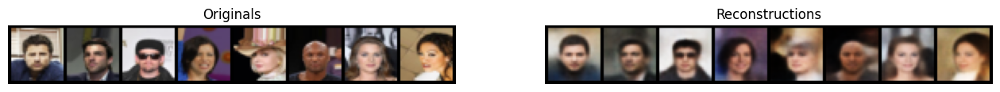

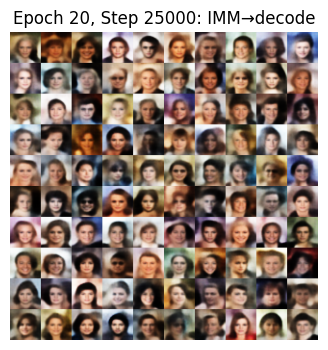

[Epoch 20/80  Step 25200]  Reconstruction=0.02132  MMD=0.02030 IMM=-0.00649
[Epoch 20/80  Step 25400]  Reconstruction=0.02160  MMD=0.02945 IMM=-0.01575
[Epoch 21/80  Step 25600]  Reconstruction=0.02106  MMD=0.02961 IMM=-0.02569
[Epoch 21/80  Step 25800]  Reconstruction=0.02134  MMD=0.02239 IMM=-0.01923
[Epoch 21/80  Step 26000]  Reconstruction=0.02088  MMD=0.02847 IMM=-0.03397


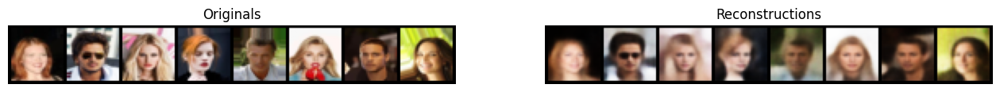

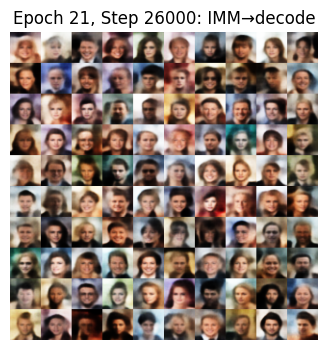

[Epoch 21/80  Step 26200]  Reconstruction=0.02065  MMD=0.03287 IMM=-0.02675
[Epoch 21/80  Step 26400]  Reconstruction=0.02103  MMD=0.02851 IMM=-0.02230
[Epoch 21/80  Step 26600]  Reconstruction=0.02106  MMD=0.02847 IMM=-0.01715
[Epoch 22/80  Step 26800]  Reconstruction=0.02153  MMD=0.02895 IMM=-0.02883
[Epoch 22/80  Step 27000]  Reconstruction=0.02134  MMD=0.05091 IMM=-0.00200


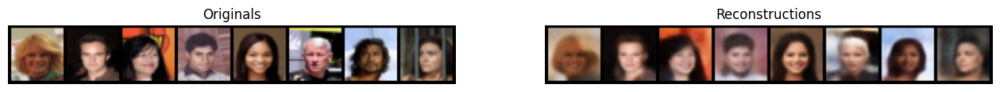

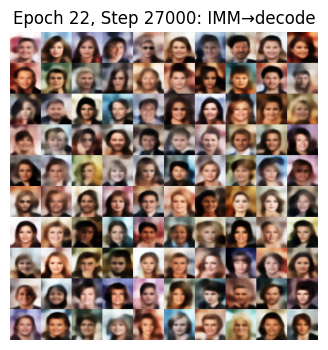

[Epoch 22/80  Step 27200]  Reconstruction=0.02170  MMD=0.02355 IMM=-0.02205
[Epoch 22/80  Step 27400]  Reconstruction=0.02068  MMD=0.02407 IMM=-0.04833
[Epoch 22/80  Step 27600]  Reconstruction=0.02024  MMD=0.04580 IMM=0.00076
[Epoch 22/80  Step 27800]  Reconstruction=0.02248  MMD=0.02255 IMM=-0.00317
[Epoch 23/80  Step 28000]  Reconstruction=0.02164  MMD=0.08723 IMM=-0.00713


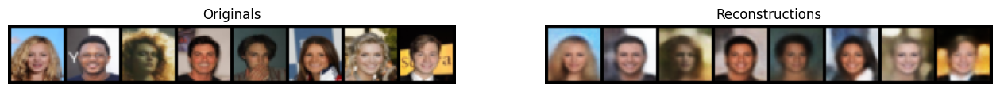

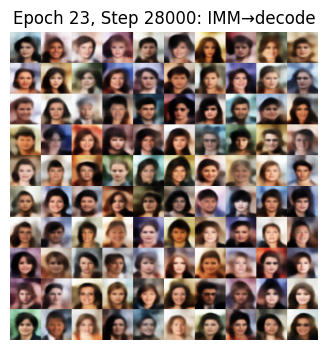

[Epoch 23/80  Step 28200]  Reconstruction=0.02065  MMD=0.04183 IMM=0.00271
[Epoch 23/80  Step 28400]  Reconstruction=0.02094  MMD=0.02081 IMM=0.00524
[Epoch 23/80  Step 28600]  Reconstruction=0.01855  MMD=0.05731 IMM=-0.02431
[Epoch 23/80  Step 28800]  Reconstruction=0.02195  MMD=0.02575 IMM=-0.01199
[Epoch 23/80  Step 29000]  Reconstruction=0.02207  MMD=0.03210 IMM=-0.00377


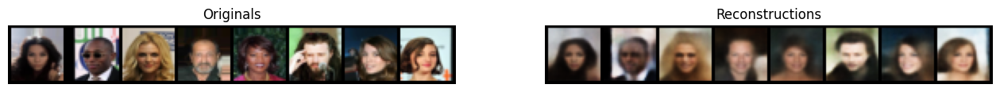

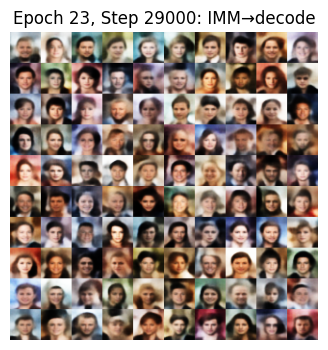

[Epoch 23/80  Step 29200]  Reconstruction=0.02070  MMD=0.02097 IMM=-0.00201
[Epoch 24/80  Step 29400]  Reconstruction=0.02049  MMD=0.06975 IMM=0.00529
[Epoch 24/80  Step 29600]  Reconstruction=0.01909  MMD=0.07599 IMM=-0.00253
[Epoch 24/80  Step 29800]  Reconstruction=0.02141  MMD=0.02883 IMM=-0.00194
[Epoch 24/80  Step 30000]  Reconstruction=0.02135  MMD=0.02924 IMM=0.01140


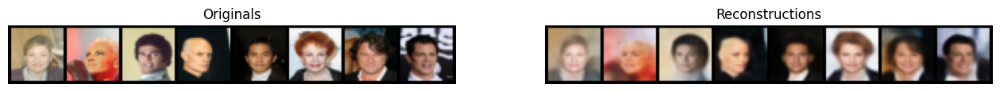

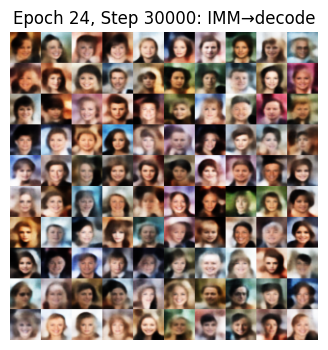

[Epoch 24/80  Step 30200]  Reconstruction=0.01967  MMD=0.01941 IMM=-0.02120
[Epoch 24/80  Step 30400]  Reconstruction=0.01978  MMD=0.03089 IMM=-0.02843
[Epoch 25/80  Step 30600]  Reconstruction=0.02298  MMD=0.02769 IMM=-0.00935
[Epoch 25/80  Step 30800]  Reconstruction=0.02209  MMD=0.02834 IMM=-0.00027
[Epoch 25/80  Step 31000]  Reconstruction=0.02233  MMD=0.03345 IMM=-0.02032


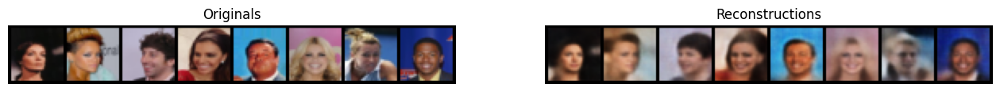

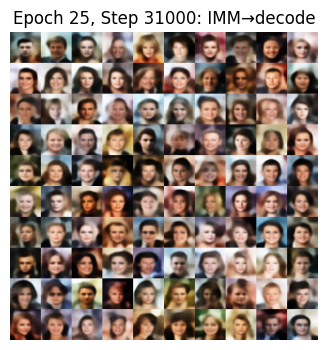

[Epoch 25/80  Step 31200]  Reconstruction=0.02135  MMD=0.05631 IMM=-0.00607
[Epoch 25/80  Step 31400]  Reconstruction=0.02095  MMD=0.01972 IMM=-0.01401
[Epoch 25/80  Step 31600]  Reconstruction=0.02097  MMD=0.07429 IMM=-0.01354
[Epoch 26/80  Step 31800]  Reconstruction=0.02127  MMD=0.02639 IMM=0.00247
[Epoch 26/80  Step 32000]  Reconstruction=0.02154  MMD=0.04574 IMM=-0.02848


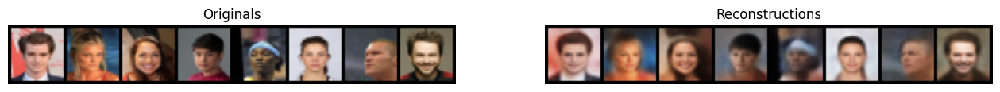

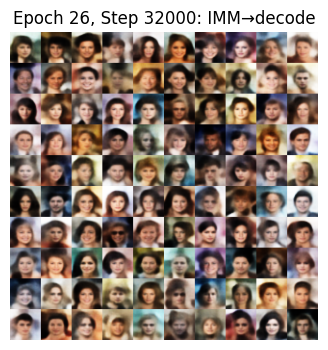

[Epoch 26/80  Step 32200]  Reconstruction=0.02171  MMD=0.03629 IMM=-0.03352
[Epoch 26/80  Step 32400]  Reconstruction=0.02015  MMD=0.02662 IMM=-0.00706
[Epoch 26/80  Step 32600]  Reconstruction=0.02072  MMD=0.11656 IMM=-0.00776
[Epoch 26/80  Step 32800]  Reconstruction=0.02065  MMD=0.02270 IMM=0.01921
[Epoch 26/80  Step 33000]  Reconstruction=0.02203  MMD=0.02876 IMM=-0.01448


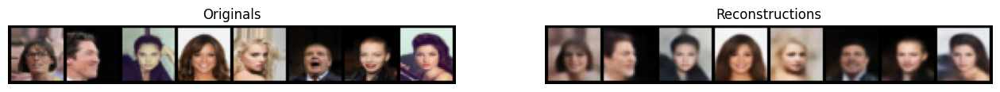

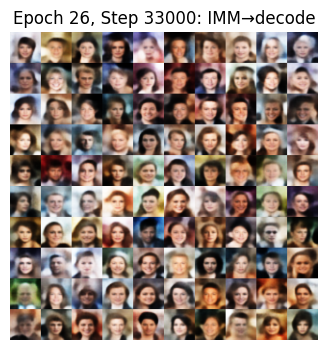

[Epoch 27/80  Step 33200]  Reconstruction=0.02035  MMD=0.02840 IMM=0.00860
[Epoch 27/80  Step 33400]  Reconstruction=0.02124  MMD=0.02657 IMM=-0.01483
[Epoch 27/80  Step 33600]  Reconstruction=0.01927  MMD=0.03501 IMM=0.00805
[Epoch 27/80  Step 33800]  Reconstruction=0.02220  MMD=0.03214 IMM=-0.01335
[Epoch 27/80  Step 34000]  Reconstruction=0.02041  MMD=0.03960 IMM=-0.00781


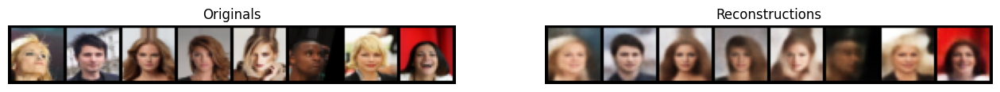

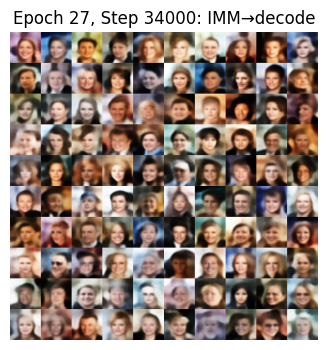

[Epoch 27/80  Step 34200]  Reconstruction=0.02029  MMD=0.02572 IMM=-0.01142
[Epoch 28/80  Step 34400]  Reconstruction=0.02247  MMD=0.03222 IMM=-0.00811
[Epoch 28/80  Step 34600]  Reconstruction=0.01968  MMD=0.07027 IMM=0.01442
[Epoch 28/80  Step 34800]  Reconstruction=0.02184  MMD=0.05932 IMM=-0.00108
[Epoch 28/80  Step 35000]  Reconstruction=0.01880  MMD=0.02403 IMM=-0.03757


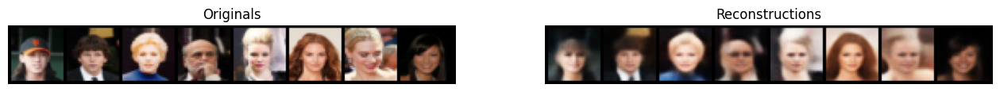

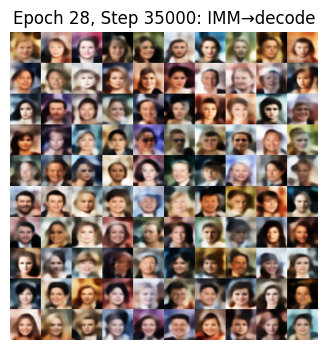

[Epoch 28/80  Step 35200]  Reconstruction=0.02033  MMD=0.04362 IMM=-0.02027
[Epoch 28/80  Step 35400]  Reconstruction=0.02164  MMD=0.02073 IMM=0.00237
[Epoch 29/80  Step 35600]  Reconstruction=0.01984  MMD=0.03532 IMM=0.00220
[Epoch 29/80  Step 35800]  Reconstruction=0.02125  MMD=0.01978 IMM=-0.02234
[Epoch 29/80  Step 36000]  Reconstruction=0.01933  MMD=0.04677 IMM=-0.00235


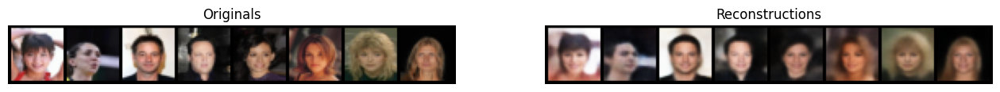

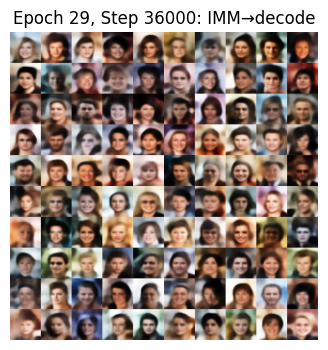

[Epoch 29/80  Step 36200]  Reconstruction=0.02092  MMD=0.03117 IMM=-0.05652
[Epoch 29/80  Step 36400]  Reconstruction=0.01961  MMD=0.02687 IMM=0.00164
[Epoch 29/80  Step 36600]  Reconstruction=0.02191  MMD=0.10150 IMM=-0.00015
[Epoch 29/80  Step 36800]  Reconstruction=0.02226  MMD=0.04041 IMM=-0.00488
[Epoch 30/80  Step 37000]  Reconstruction=0.01965  MMD=0.04620 IMM=0.00881


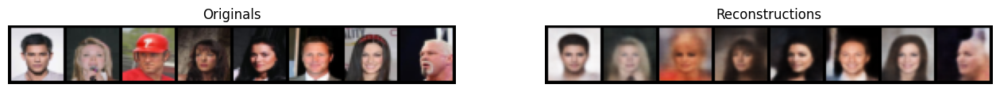

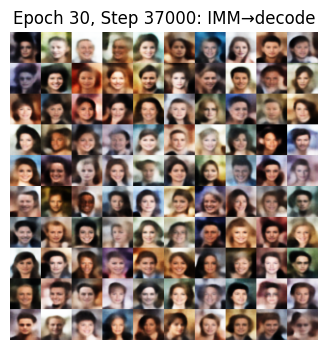

[Epoch 30/80  Step 37200]  Reconstruction=0.02223  MMD=0.04985 IMM=0.01404
[Epoch 30/80  Step 37400]  Reconstruction=0.01905  MMD=0.03766 IMM=-0.04374
[Epoch 30/80  Step 37600]  Reconstruction=0.02138  MMD=0.07160 IMM=-0.01544
[Epoch 30/80  Step 37800]  Reconstruction=0.02073  MMD=0.02564 IMM=-0.01525
[Epoch 30/80  Step 38000]  Reconstruction=0.02009  MMD=0.03736 IMM=-0.01394


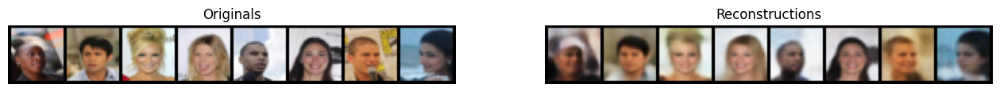

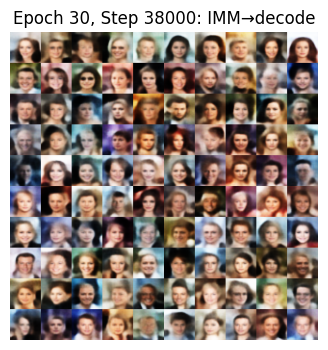

[Epoch 31/80  Step 38200]  Reconstruction=0.02218  MMD=0.04436 IMM=-0.00819
[Epoch 31/80  Step 38400]  Reconstruction=0.02212  MMD=0.04834 IMM=-0.01430
[Epoch 31/80  Step 38600]  Reconstruction=0.01980  MMD=0.02987 IMM=-0.01190
[Epoch 31/80  Step 38800]  Reconstruction=0.01943  MMD=0.13699 IMM=0.00131
[Epoch 31/80  Step 39000]  Reconstruction=0.02108  MMD=0.08909 IMM=-0.03973


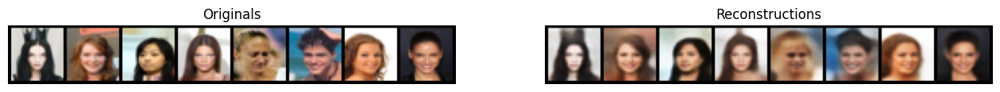

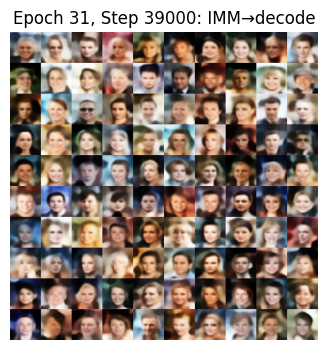

[Epoch 31/80  Step 39200]  Reconstruction=0.02180  MMD=0.02728 IMM=-0.00456
[Epoch 31/80  Step 39400]  Reconstruction=0.02177  MMD=0.07949 IMM=-0.00541
[Epoch 32/80  Step 39600]  Reconstruction=0.02013  MMD=0.04498 IMM=-0.00272
[Epoch 32/80  Step 39800]  Reconstruction=0.02054  MMD=0.03308 IMM=-0.00887
[Epoch 32/80  Step 40000]  Reconstruction=0.02149  MMD=0.02918 IMM=0.01346


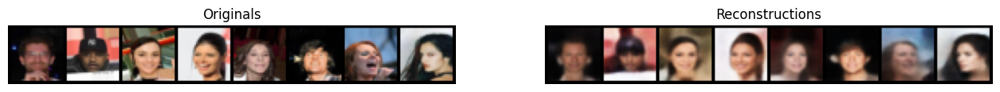

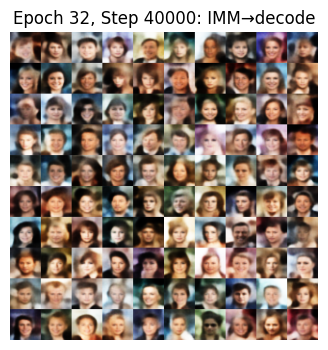

[Epoch 32/80  Step 40200]  Reconstruction=0.01899  MMD=0.02689 IMM=0.00360
[Epoch 32/80  Step 40400]  Reconstruction=0.02149  MMD=0.04050 IMM=-0.02056
[Epoch 32/80  Step 40600]  Reconstruction=0.01966  MMD=0.06302 IMM=-0.00239
[Epoch 33/80  Step 40800]  Reconstruction=0.02125  MMD=0.02287 IMM=-0.02316
[Epoch 33/80  Step 41000]  Reconstruction=0.02071  MMD=0.09739 IMM=-0.00383


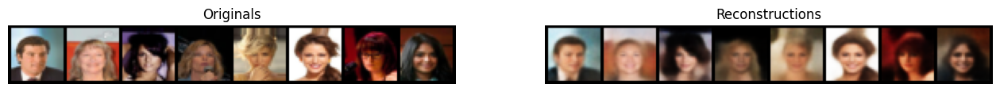

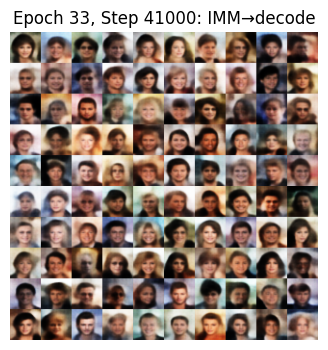

[Epoch 33/80  Step 41200]  Reconstruction=0.02102  MMD=0.02654 IMM=-0.02911
[Epoch 33/80  Step 41400]  Reconstruction=0.02121  MMD=0.05970 IMM=-0.03558
[Epoch 33/80  Step 41600]  Reconstruction=0.01954  MMD=0.03465 IMM=-0.01032
[Epoch 33/80  Step 41800]  Reconstruction=0.01969  MMD=0.04568 IMM=0.01114
[Epoch 34/80  Step 42000]  Reconstruction=0.02185  MMD=0.03887 IMM=-0.01932


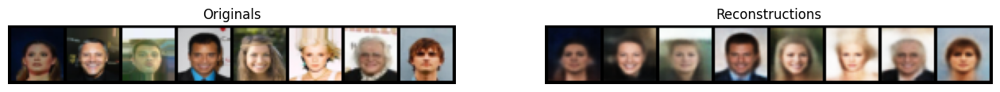

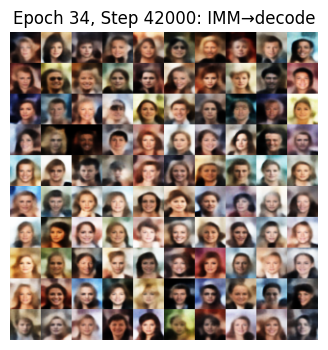

[Epoch 34/80  Step 42200]  Reconstruction=0.02160  MMD=0.05027 IMM=-0.02359
[Epoch 34/80  Step 42400]  Reconstruction=0.02012  MMD=0.05251 IMM=-0.03140
[Epoch 34/80  Step 42600]  Reconstruction=0.01902  MMD=0.03670 IMM=0.01973
[Epoch 34/80  Step 42800]  Reconstruction=0.02018  MMD=0.02733 IMM=0.00457
[Epoch 34/80  Step 43000]  Reconstruction=0.02050  MMD=0.02389 IMM=-0.00435


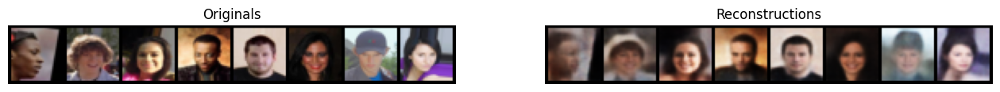

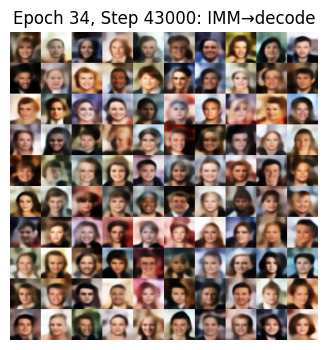

[Epoch 34/80  Step 43200]  Reconstruction=0.01884  MMD=0.02509 IMM=-0.00901
[Epoch 35/80  Step 43400]  Reconstruction=0.01954  MMD=0.02694 IMM=-0.03092
[Epoch 35/80  Step 43600]  Reconstruction=0.02108  MMD=0.07580 IMM=-0.00242
[Epoch 35/80  Step 43800]  Reconstruction=0.01994  MMD=0.04287 IMM=0.01097
[Epoch 35/80  Step 44000]  Reconstruction=0.02097  MMD=0.15597 IMM=-0.02234


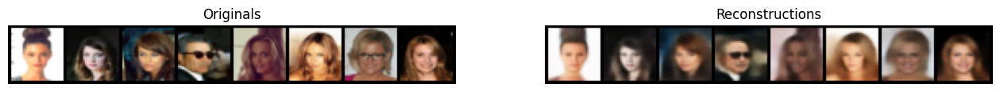

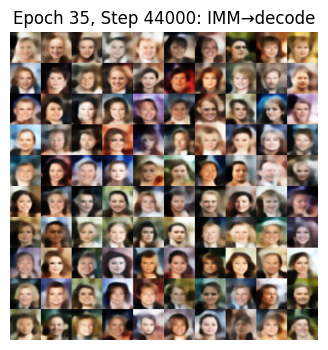

[Epoch 35/80  Step 44200]  Reconstruction=0.01934  MMD=0.02893 IMM=-0.00388
[Epoch 35/80  Step 44400]  Reconstruction=0.01981  MMD=0.05193 IMM=-0.01591
[Epoch 36/80  Step 44600]  Reconstruction=0.02066  MMD=0.03251 IMM=-0.01805
[Epoch 36/80  Step 44800]  Reconstruction=0.02047  MMD=0.04509 IMM=-0.00653
[Epoch 36/80  Step 45000]  Reconstruction=0.02123  MMD=0.03679 IMM=0.00209


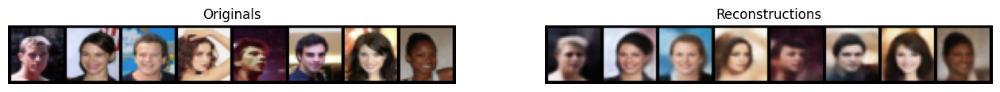

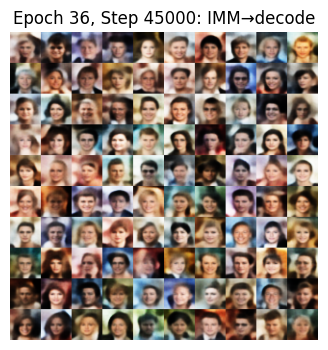

[Epoch 36/80  Step 45200]  Reconstruction=0.02049  MMD=0.03858 IMM=-0.01057
[Epoch 36/80  Step 45400]  Reconstruction=0.02084  MMD=0.05572 IMM=0.00303
[Epoch 36/80  Step 45600]  Reconstruction=0.02068  MMD=0.01894 IMM=0.00091
[Epoch 37/80  Step 45800]  Reconstruction=0.02018  MMD=0.06013 IMM=-0.00097
[Epoch 37/80  Step 46000]  Reconstruction=0.01984  MMD=0.02091 IMM=-0.03484


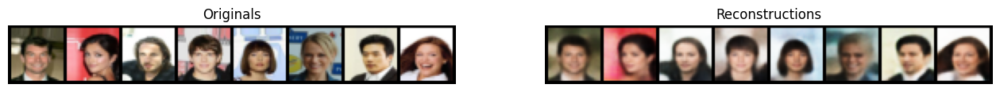

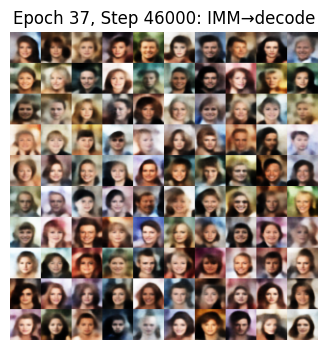

[Epoch 37/80  Step 46200]  Reconstruction=0.02059  MMD=0.03343 IMM=-0.00293
[Epoch 37/80  Step 46400]  Reconstruction=0.02079  MMD=0.03279 IMM=-0.00699
[Epoch 37/80  Step 46600]  Reconstruction=0.01751  MMD=0.02867 IMM=-0.03614
[Epoch 37/80  Step 46800]  Reconstruction=0.01860  MMD=0.03040 IMM=0.00703
[Epoch 37/80  Step 47000]  Reconstruction=0.02081  MMD=0.06099 IMM=0.00031


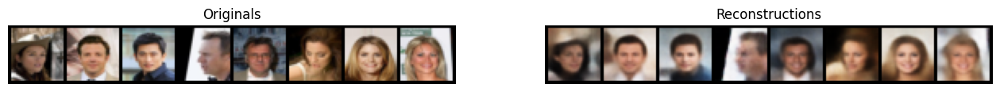

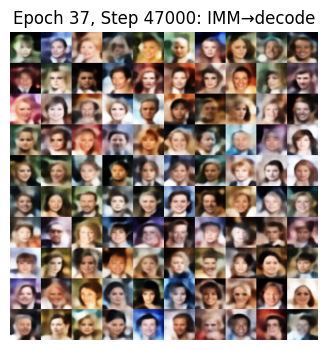

[Epoch 38/80  Step 47200]  Reconstruction=0.01944  MMD=0.06288 IMM=-0.01973
[Epoch 38/80  Step 47400]  Reconstruction=0.01912  MMD=0.05643 IMM=0.00136
[Epoch 38/80  Step 47600]  Reconstruction=0.02054  MMD=0.07101 IMM=-0.00850
[Epoch 38/80  Step 47800]  Reconstruction=0.01981  MMD=0.03436 IMM=0.00323
[Epoch 38/80  Step 48000]  Reconstruction=0.02115  MMD=0.03515 IMM=-0.00723


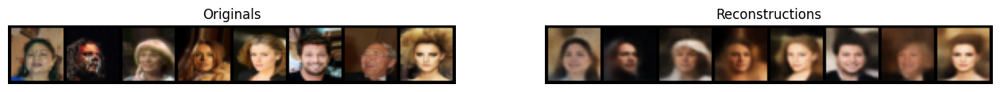

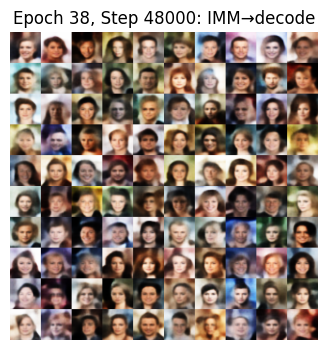

[Epoch 38/80  Step 48200]  Reconstruction=0.02248  MMD=0.03942 IMM=-0.00302
[Epoch 39/80  Step 48400]  Reconstruction=0.02013  MMD=0.03705 IMM=0.00553
[Epoch 39/80  Step 48600]  Reconstruction=0.01987  MMD=0.04525 IMM=-0.01423
[Epoch 39/80  Step 48800]  Reconstruction=0.01873  MMD=0.02672 IMM=0.00341
[Epoch 39/80  Step 49000]  Reconstruction=0.02064  MMD=0.03260 IMM=-0.00380


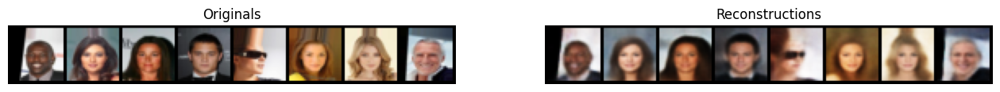

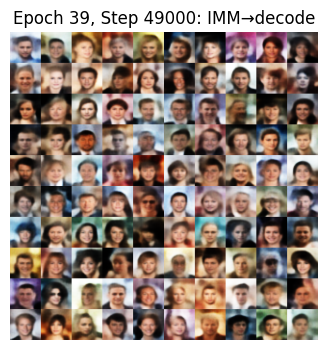

[Epoch 39/80  Step 49200]  Reconstruction=0.01893  MMD=0.05387 IMM=-0.00620
[Epoch 39/80  Step 49400]  Reconstruction=0.01901  MMD=0.02250 IMM=-0.02089
[Epoch 40/80  Step 49600]  Reconstruction=0.02027  MMD=0.07249 IMM=-0.03442
[Epoch 40/80  Step 49800]  Reconstruction=0.02000  MMD=0.04377 IMM=-0.00232
[Epoch 40/80  Step 50000]  Reconstruction=0.02043  MMD=0.02749 IMM=0.00893


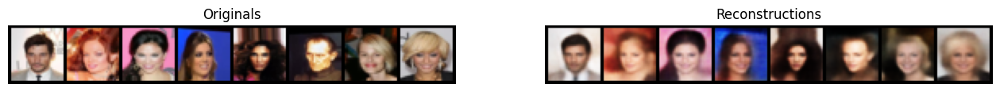

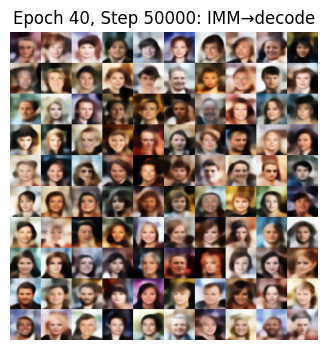

[Epoch 40/80  Step 50200]  Reconstruction=0.02130  MMD=0.02844 IMM=-0.01575
[Epoch 40/80  Step 50400]  Reconstruction=0.01965  MMD=0.07598 IMM=-0.01462
[Epoch 40/80  Step 50600]  Reconstruction=0.01965  MMD=0.04202 IMM=-0.00117
[Epoch 40/80  Step 50800]  Reconstruction=0.02056  MMD=0.04708 IMM=0.00221
[Epoch 41/80  Step 51000]  Reconstruction=0.01997  MMD=0.03250 IMM=0.00733


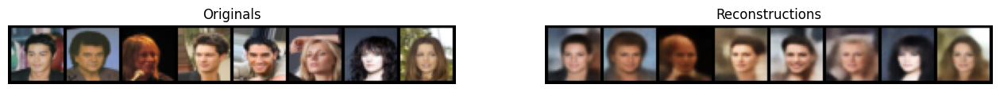

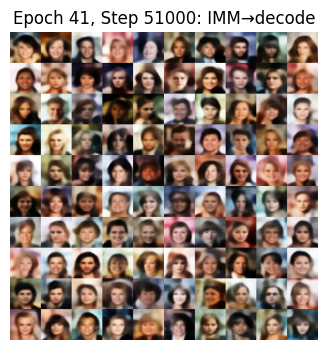

[Epoch 41/80  Step 51200]  Reconstruction=0.02005  MMD=0.07892 IMM=0.00242
[Epoch 41/80  Step 51400]  Reconstruction=0.01792  MMD=0.02650 IMM=-0.00239
[Epoch 41/80  Step 51600]  Reconstruction=0.02007  MMD=0.02897 IMM=-0.01796
[Epoch 41/80  Step 51800]  Reconstruction=0.01988  MMD=0.05948 IMM=-0.02203
[Epoch 41/80  Step 52000]  Reconstruction=0.01977  MMD=0.10114 IMM=-0.00230


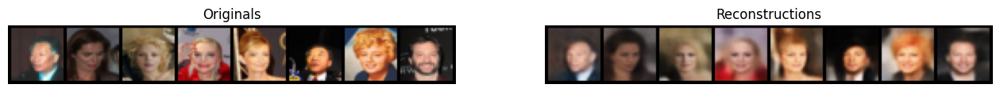

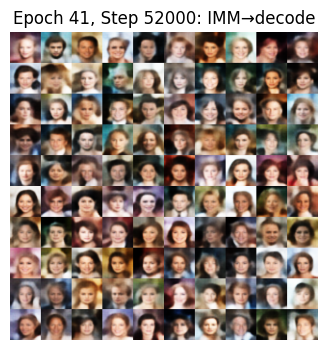

[Epoch 42/80  Step 52200]  Reconstruction=0.02146  MMD=0.06214 IMM=-0.01698
[Epoch 42/80  Step 52400]  Reconstruction=0.02153  MMD=0.02963 IMM=-0.00405
[Epoch 42/80  Step 52600]  Reconstruction=0.01992  MMD=0.06507 IMM=0.00086
[Epoch 42/80  Step 52800]  Reconstruction=0.01878  MMD=0.03275 IMM=0.00411
[Epoch 42/80  Step 53000]  Reconstruction=0.02107  MMD=0.02742 IMM=-0.00632


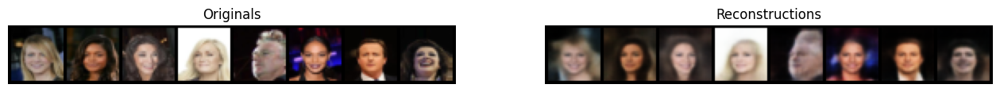

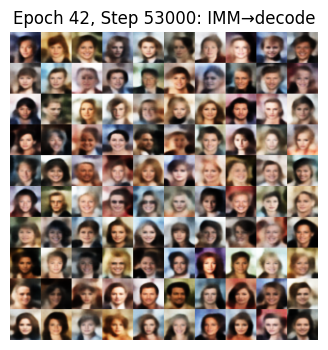

[Epoch 42/80  Step 53200]  Reconstruction=0.01964  MMD=0.05061 IMM=-0.01154
[Epoch 43/80  Step 53400]  Reconstruction=0.02126  MMD=0.04072 IMM=-0.00767
[Epoch 43/80  Step 53600]  Reconstruction=0.01990  MMD=0.04175 IMM=0.00296
[Epoch 43/80  Step 53800]  Reconstruction=0.01948  MMD=0.04529 IMM=-0.00215
[Epoch 43/80  Step 54000]  Reconstruction=0.01838  MMD=0.01807 IMM=-0.00094


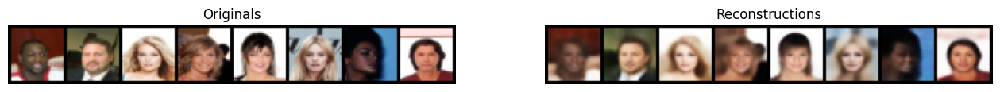

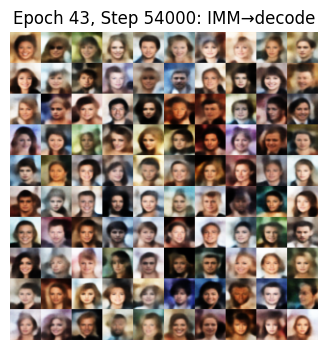

[Epoch 43/80  Step 54200]  Reconstruction=0.01869  MMD=0.02553 IMM=-0.00733
[Epoch 43/80  Step 54400]  Reconstruction=0.02106  MMD=0.03075 IMM=0.00502
[Epoch 43/80  Step 54600]  Reconstruction=0.02209  MMD=0.03218 IMM=-0.00971
[Epoch 44/80  Step 54800]  Reconstruction=0.01948  MMD=0.06536 IMM=-0.04774
[Epoch 44/80  Step 55000]  Reconstruction=0.02004  MMD=0.06706 IMM=0.00466


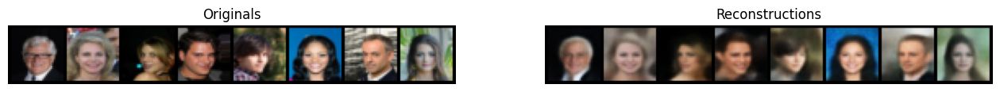

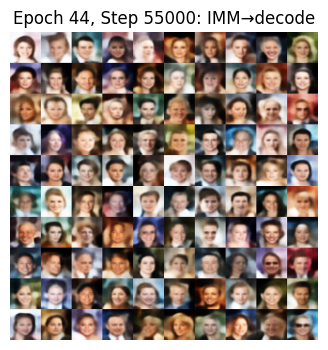

[Epoch 44/80  Step 55200]  Reconstruction=0.01786  MMD=0.02793 IMM=-0.00175
[Epoch 44/80  Step 55400]  Reconstruction=0.01918  MMD=0.06496 IMM=0.01597
[Epoch 44/80  Step 55600]  Reconstruction=0.02069  MMD=0.06284 IMM=-0.01849
[Epoch 44/80  Step 55800]  Reconstruction=0.02023  MMD=0.02766 IMM=-0.00099
[Epoch 45/80  Step 56000]  Reconstruction=0.01937  MMD=0.06932 IMM=-0.01635


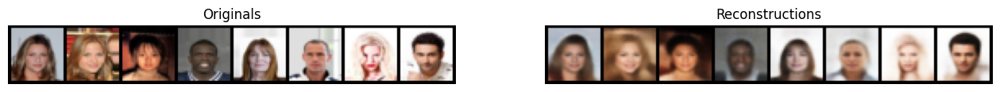

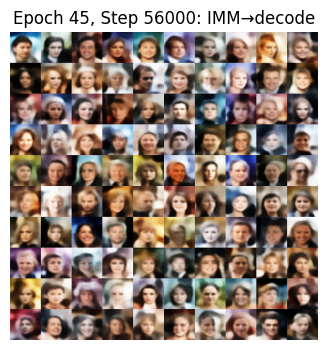

[Epoch 45/80  Step 56200]  Reconstruction=0.01976  MMD=0.02665 IMM=-0.02446
[Epoch 45/80  Step 56400]  Reconstruction=0.02015  MMD=0.03910 IMM=-0.02390
[Epoch 45/80  Step 56600]  Reconstruction=0.02226  MMD=0.03875 IMM=-0.00940
[Epoch 45/80  Step 56800]  Reconstruction=0.01858  MMD=0.03040 IMM=0.00202
[Epoch 45/80  Step 57000]  Reconstruction=0.01887  MMD=0.06969 IMM=0.00051


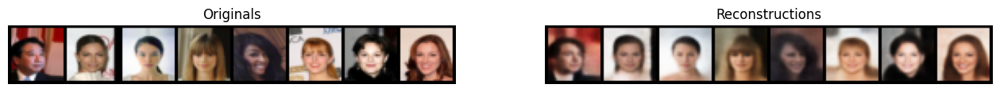

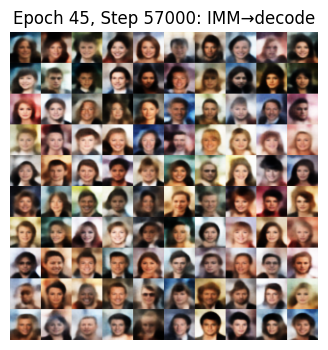

[Epoch 46/80  Step 57200]  Reconstruction=0.01941  MMD=0.02580 IMM=-0.02375
[Epoch 46/80  Step 57400]  Reconstruction=0.01937  MMD=0.06346 IMM=0.00126
[Epoch 46/80  Step 57600]  Reconstruction=0.01784  MMD=0.05819 IMM=-0.01387
[Epoch 46/80  Step 57800]  Reconstruction=0.01985  MMD=0.02914 IMM=-0.01205
[Epoch 46/80  Step 58000]  Reconstruction=0.02148  MMD=0.01578 IMM=0.00407


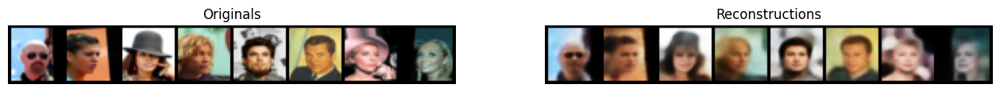

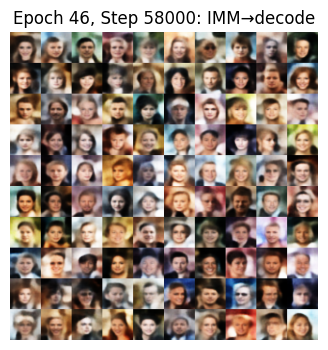

[Epoch 46/80  Step 58200]  Reconstruction=0.02024  MMD=0.03672 IMM=-0.00655
[Epoch 46/80  Step 58400]  Reconstruction=0.02057  MMD=0.03422 IMM=-0.02094
[Epoch 47/80  Step 58600]  Reconstruction=0.01946  MMD=0.02537 IMM=-0.06136
[Epoch 47/80  Step 58800]  Reconstruction=0.01970  MMD=0.03386 IMM=-0.00397
[Epoch 47/80  Step 59000]  Reconstruction=0.01805  MMD=0.06346 IMM=-0.01306


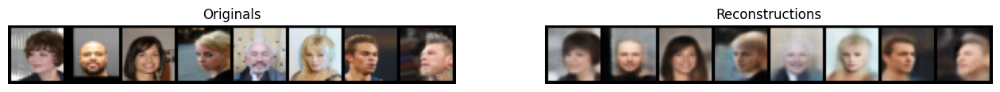

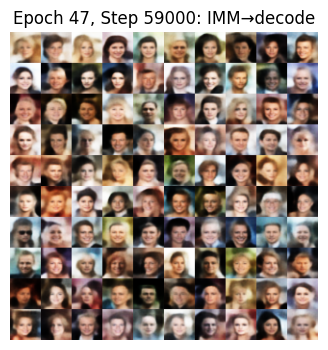

[Epoch 47/80  Step 59200]  Reconstruction=0.01889  MMD=0.03965 IMM=0.00148
[Epoch 47/80  Step 59400]  Reconstruction=0.02003  MMD=0.02715 IMM=0.00500
[Epoch 47/80  Step 59600]  Reconstruction=0.02026  MMD=0.03517 IMM=0.00905
[Epoch 48/80  Step 59800]  Reconstruction=0.02136  MMD=0.02939 IMM=-0.00221
[Epoch 48/80  Step 60000]  Reconstruction=0.01902  MMD=0.04688 IMM=0.00104


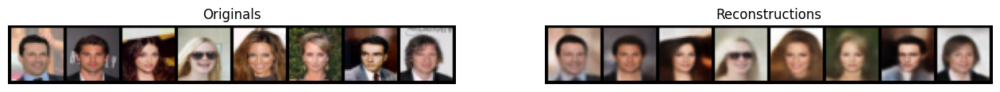

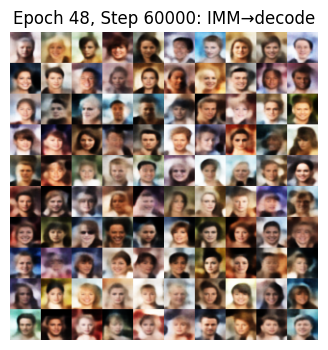

[Epoch 48/80  Step 60200]  Reconstruction=0.01840  MMD=0.09146 IMM=-0.02127
[Epoch 48/80  Step 60400]  Reconstruction=0.01963  MMD=0.08657 IMM=0.00382
[Epoch 48/80  Step 60600]  Reconstruction=0.02103  MMD=0.02816 IMM=0.01213
[Epoch 48/80  Step 60800]  Reconstruction=0.02000  MMD=0.07612 IMM=-0.03248
[Epoch 48/80  Step 61000]  Reconstruction=0.01971  MMD=0.03540 IMM=-0.00217


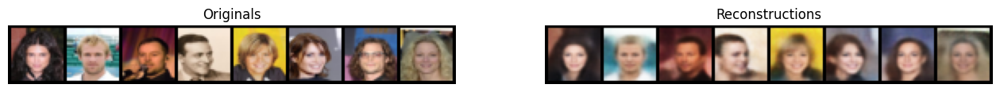

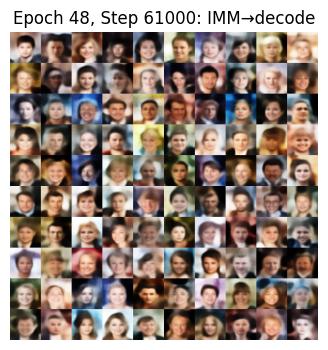

[Epoch 49/80  Step 61200]  Reconstruction=0.01951  MMD=0.02808 IMM=0.00375
[Epoch 49/80  Step 61400]  Reconstruction=0.01903  MMD=0.04518 IMM=0.00628
[Epoch 49/80  Step 61600]  Reconstruction=0.01949  MMD=0.08141 IMM=-0.00342
[Epoch 49/80  Step 61800]  Reconstruction=0.02004  MMD=0.02266 IMM=0.00936
[Epoch 49/80  Step 62000]  Reconstruction=0.02146  MMD=0.04692 IMM=-0.00438


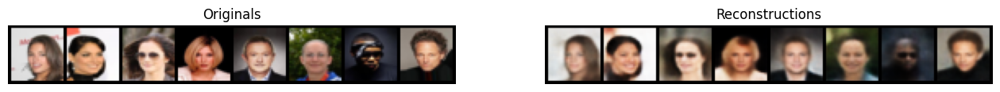

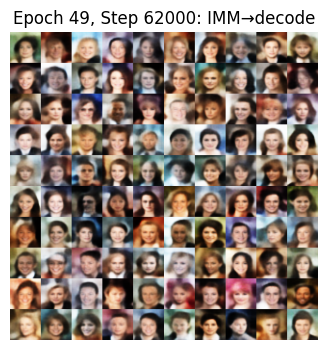

[Epoch 49/80  Step 62200]  Reconstruction=0.02092  MMD=0.02514 IMM=0.00871
[Epoch 50/80  Step 62400]  Reconstruction=0.01863  MMD=0.02845 IMM=-0.00018
[Epoch 50/80  Step 62600]  Reconstruction=0.02020  MMD=0.05128 IMM=0.00076
[Epoch 50/80  Step 62800]  Reconstruction=0.01975  MMD=0.10852 IMM=-0.01439
[Epoch 50/80  Step 63000]  Reconstruction=0.02157  MMD=0.04636 IMM=-0.00808


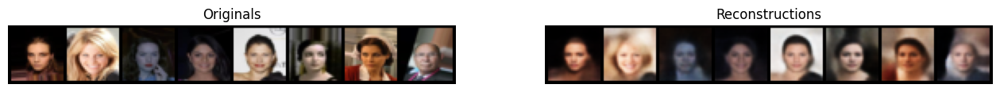

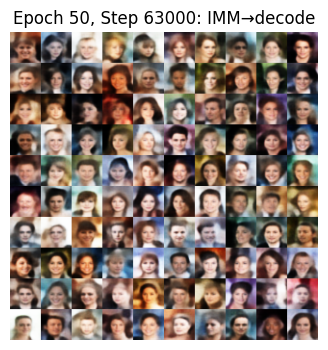

[Epoch 50/80  Step 63200]  Reconstruction=0.01939  MMD=0.04482 IMM=0.00519
[Epoch 50/80  Step 63400]  Reconstruction=0.01938  MMD=0.04111 IMM=0.00000
[Epoch 51/80  Step 63600]  Reconstruction=0.01919  MMD=0.03337 IMM=0.00159
[Epoch 51/80  Step 63800]  Reconstruction=0.02047  MMD=0.08639 IMM=0.00215
[Epoch 51/80  Step 64000]  Reconstruction=0.01916  MMD=0.03879 IMM=-0.00291


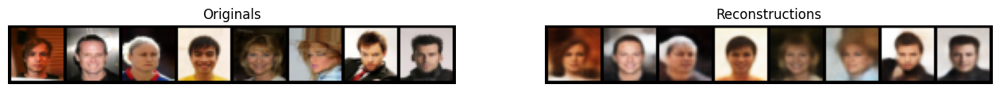

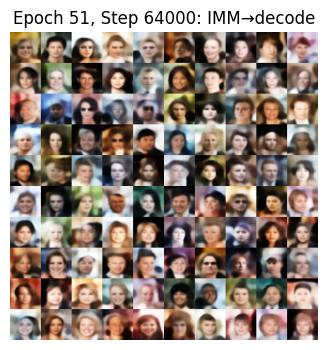

[Epoch 51/80  Step 64200]  Reconstruction=0.01854  MMD=0.02971 IMM=0.00156
[Epoch 51/80  Step 64400]  Reconstruction=0.02055  MMD=0.05234 IMM=-0.00371
[Epoch 51/80  Step 64600]  Reconstruction=0.02069  MMD=0.17437 IMM=0.00096
[Epoch 51/80  Step 64800]  Reconstruction=0.01923  MMD=0.05931 IMM=0.00326
[Epoch 52/80  Step 65000]  Reconstruction=0.02010  MMD=0.05669 IMM=-0.00068


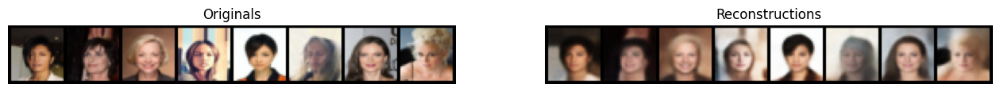

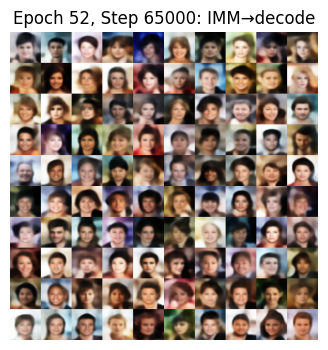

[Epoch 52/80  Step 65200]  Reconstruction=0.01872  MMD=0.03224 IMM=0.00555
[Epoch 52/80  Step 65400]  Reconstruction=0.02019  MMD=0.04095 IMM=-0.02347
[Epoch 52/80  Step 65600]  Reconstruction=0.02098  MMD=0.10185 IMM=-0.00496
[Epoch 52/80  Step 65800]  Reconstruction=0.02099  MMD=0.07252 IMM=0.01629
[Epoch 52/80  Step 66000]  Reconstruction=0.01929  MMD=0.03197 IMM=-0.01381


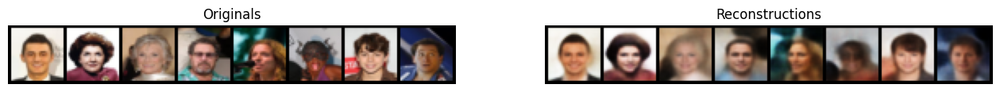

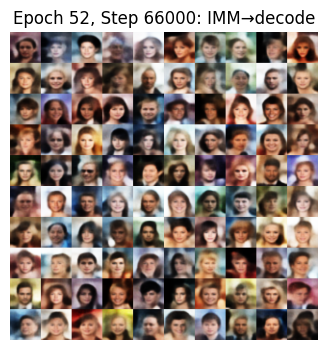

[Epoch 53/80  Step 66200]  Reconstruction=0.01794  MMD=0.03531 IMM=0.00544
[Epoch 53/80  Step 66400]  Reconstruction=0.02080  MMD=0.04608 IMM=0.00061
[Epoch 53/80  Step 66600]  Reconstruction=0.01850  MMD=0.02861 IMM=-0.02631
[Epoch 53/80  Step 66800]  Reconstruction=0.02051  MMD=0.02844 IMM=-0.01032
[Epoch 53/80  Step 67000]  Reconstruction=0.02019  MMD=0.02999 IMM=-0.01396


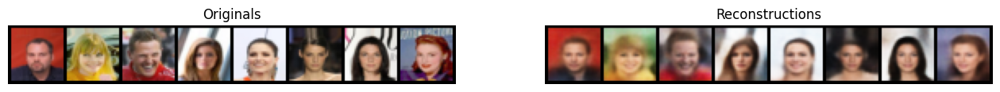

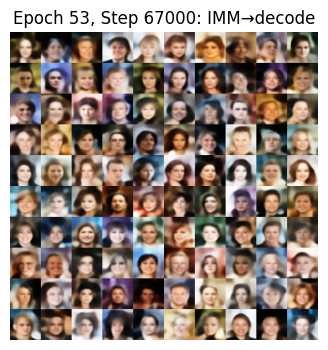

[Epoch 53/80  Step 67200]  Reconstruction=0.01894  MMD=0.02599 IMM=-0.06659
[Epoch 54/80  Step 67400]  Reconstruction=0.01936  MMD=0.03657 IMM=-0.00549
[Epoch 54/80  Step 67600]  Reconstruction=0.01972  MMD=0.07891 IMM=-0.03127
[Epoch 54/80  Step 67800]  Reconstruction=0.02109  MMD=0.04023 IMM=-0.00368
[Epoch 54/80  Step 68000]  Reconstruction=0.02007  MMD=0.11184 IMM=-0.01244


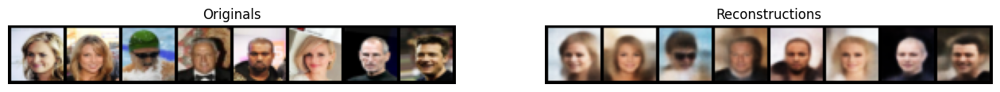

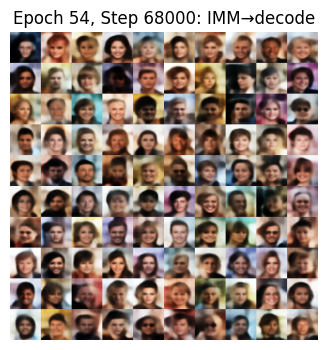

[Epoch 54/80  Step 68200]  Reconstruction=0.01931  MMD=0.07745 IMM=-0.01405
[Epoch 54/80  Step 68400]  Reconstruction=0.01939  MMD=0.05881 IMM=0.00318
[Epoch 54/80  Step 68600]  Reconstruction=0.01909  MMD=0.07323 IMM=-0.00162
[Epoch 55/80  Step 68800]  Reconstruction=0.01824  MMD=0.02463 IMM=-0.00061
[Epoch 55/80  Step 69000]  Reconstruction=0.01999  MMD=0.01820 IMM=-0.02557


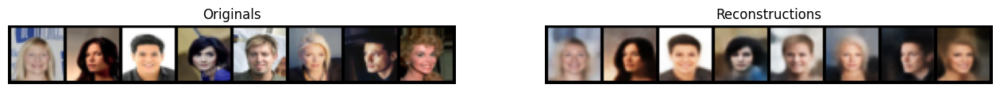

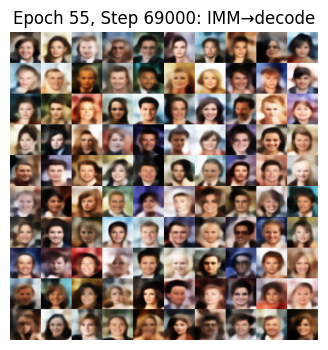

[Epoch 55/80  Step 69200]  Reconstruction=0.02071  MMD=0.02346 IMM=0.00174
[Epoch 55/80  Step 69400]  Reconstruction=0.02212  MMD=0.05083 IMM=0.01435
[Epoch 55/80  Step 69600]  Reconstruction=0.01900  MMD=0.05979 IMM=-0.04194
[Epoch 55/80  Step 69800]  Reconstruction=0.02143  MMD=0.02853 IMM=0.00172
[Epoch 56/80  Step 70000]  Reconstruction=0.02080  MMD=0.08737 IMM=0.00914


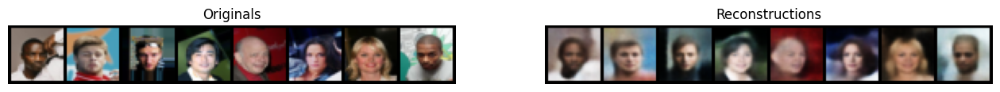

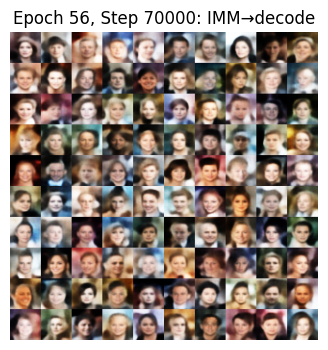

[Epoch 56/80  Step 70200]  Reconstruction=0.01935  MMD=0.03937 IMM=0.02186
[Epoch 56/80  Step 70400]  Reconstruction=0.02001  MMD=0.02557 IMM=0.00907
[Epoch 56/80  Step 70600]  Reconstruction=0.01833  MMD=0.02447 IMM=0.01039
[Epoch 56/80  Step 70800]  Reconstruction=0.01882  MMD=0.05861 IMM=0.01423
[Epoch 56/80  Step 71000]  Reconstruction=0.01749  MMD=0.03948 IMM=0.00134


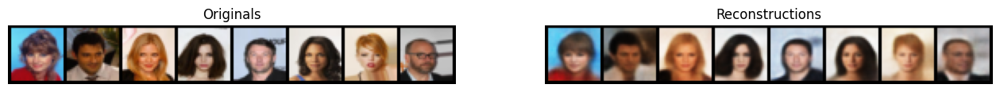

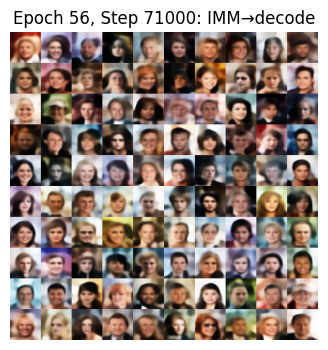

[Epoch 57/80  Step 71200]  Reconstruction=0.02108  MMD=0.02142 IMM=-0.02655
[Epoch 57/80  Step 71400]  Reconstruction=0.01862  MMD=0.03939 IMM=-0.00253
[Epoch 57/80  Step 71600]  Reconstruction=0.01940  MMD=0.04087 IMM=0.00161
[Epoch 57/80  Step 71800]  Reconstruction=0.02013  MMD=0.08773 IMM=0.00429
[Epoch 57/80  Step 72000]  Reconstruction=0.01879  MMD=0.05727 IMM=-0.00224


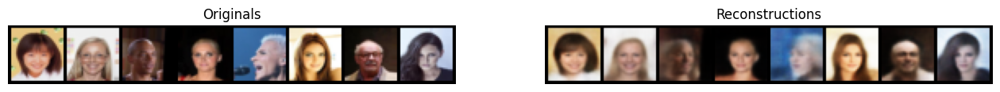

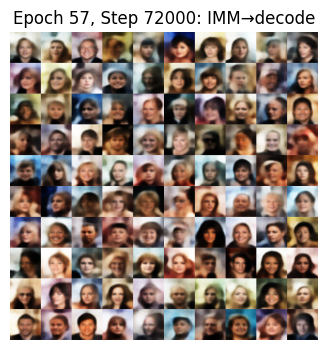

[Epoch 57/80  Step 72200]  Reconstruction=0.02113  MMD=0.02365 IMM=-0.00741
[Epoch 57/80  Step 72400]  Reconstruction=0.01905  MMD=0.09192 IMM=0.00551
[Epoch 58/80  Step 72600]  Reconstruction=0.02020  MMD=0.04864 IMM=0.00259
[Epoch 58/80  Step 72800]  Reconstruction=0.01864  MMD=0.03702 IMM=0.00363
[Epoch 58/80  Step 73000]  Reconstruction=0.01958  MMD=0.05450 IMM=-0.05019


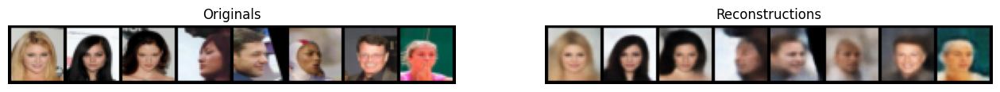

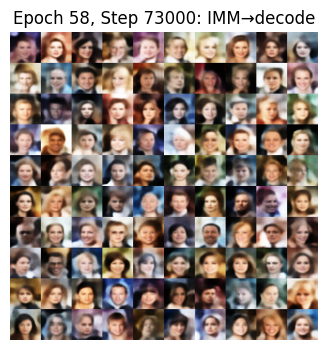

[Epoch 58/80  Step 73200]  Reconstruction=0.01902  MMD=0.03897 IMM=0.00763
[Epoch 58/80  Step 73400]  Reconstruction=0.02003  MMD=0.03911 IMM=0.00197
[Epoch 58/80  Step 73600]  Reconstruction=0.01933  MMD=0.04577 IMM=0.00781
[Epoch 59/80  Step 73800]  Reconstruction=0.02021  MMD=0.03528 IMM=0.00482
[Epoch 59/80  Step 74000]  Reconstruction=0.01991  MMD=0.06000 IMM=0.00269


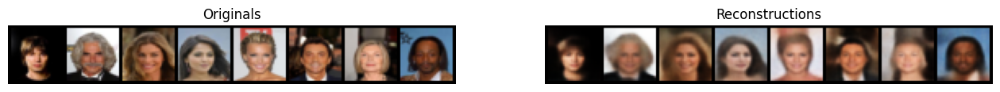

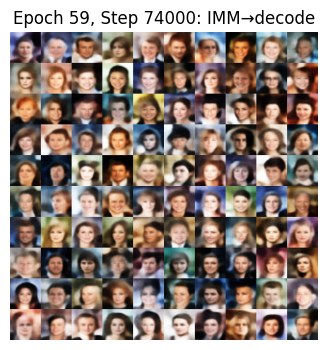

[Epoch 59/80  Step 74200]  Reconstruction=0.01886  MMD=0.02612 IMM=0.00289
[Epoch 59/80  Step 74400]  Reconstruction=0.01724  MMD=0.02224 IMM=0.00468
[Epoch 59/80  Step 74600]  Reconstruction=0.01988  MMD=0.02939 IMM=0.00972
[Epoch 59/80  Step 74800]  Reconstruction=0.01834  MMD=0.02941 IMM=0.00718
[Epoch 60/80  Step 75000]  Reconstruction=0.01977  MMD=0.06781 IMM=-0.00273


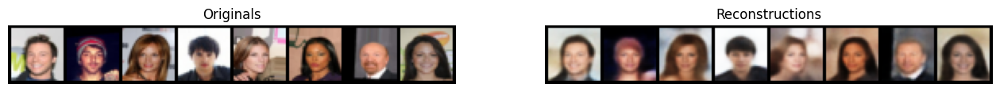

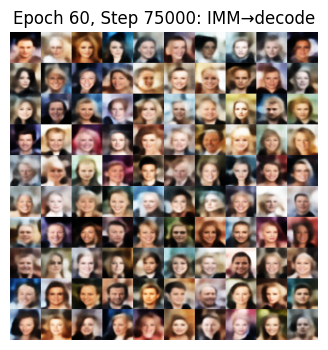

[Epoch 60/80  Step 75200]  Reconstruction=0.02025  MMD=0.07944 IMM=-0.00038
[Epoch 60/80  Step 75400]  Reconstruction=0.01996  MMD=0.02473 IMM=-0.00350
[Epoch 60/80  Step 75600]  Reconstruction=0.01947  MMD=0.07980 IMM=-0.00060
[Epoch 60/80  Step 75800]  Reconstruction=0.01839  MMD=0.03872 IMM=0.00586
[Epoch 60/80  Step 76000]  Reconstruction=0.02281  MMD=0.06508 IMM=-0.01821


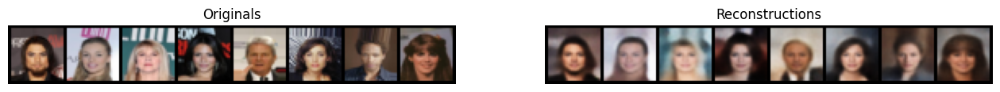

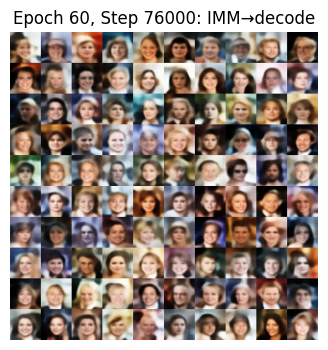

[Epoch 60/80  Step 76200]  Reconstruction=0.01913  MMD=0.03348 IMM=-0.00211
[Epoch 61/80  Step 76400]  Reconstruction=0.01964  MMD=0.02810 IMM=-0.00118
[Epoch 61/80  Step 76600]  Reconstruction=0.01866  MMD=0.03619 IMM=0.01633
[Epoch 61/80  Step 76800]  Reconstruction=0.01960  MMD=0.02805 IMM=0.01072
[Epoch 61/80  Step 77000]  Reconstruction=0.01877  MMD=0.02658 IMM=0.01176


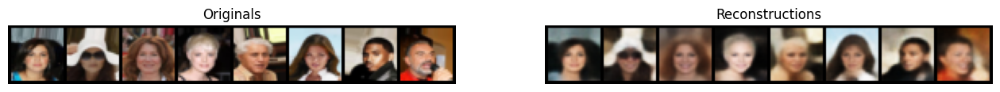

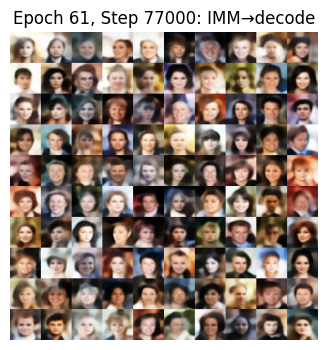

[Epoch 61/80  Step 77200]  Reconstruction=0.02044  MMD=0.02545 IMM=-0.00025
[Epoch 61/80  Step 77400]  Reconstruction=0.01977  MMD=0.02728 IMM=0.01029
[Epoch 62/80  Step 77600]  Reconstruction=0.02117  MMD=0.02744 IMM=0.00281
[Epoch 62/80  Step 77800]  Reconstruction=0.01823  MMD=0.06187 IMM=0.00734
[Epoch 62/80  Step 78000]  Reconstruction=0.01839  MMD=0.02409 IMM=0.00672


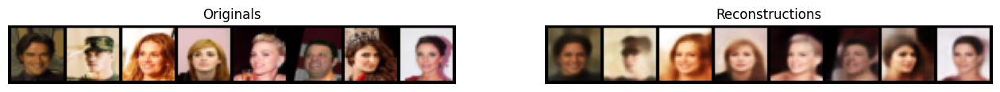

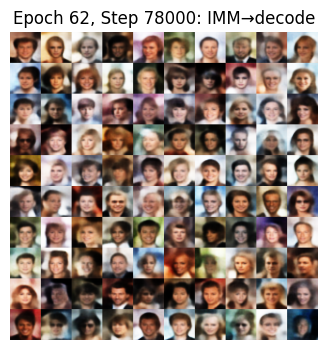

[Epoch 62/80  Step 78200]  Reconstruction=0.02009  MMD=0.03321 IMM=-0.00489
[Epoch 62/80  Step 78400]  Reconstruction=0.02033  MMD=0.04762 IMM=-0.02937
[Epoch 62/80  Step 78600]  Reconstruction=0.01973  MMD=0.03038 IMM=0.01294
[Epoch 62/80  Step 78800]  Reconstruction=0.01863  MMD=0.02092 IMM=-0.00182
[Epoch 63/80  Step 79000]  Reconstruction=0.01900  MMD=0.02296 IMM=0.01083


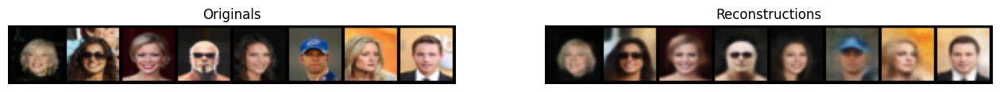

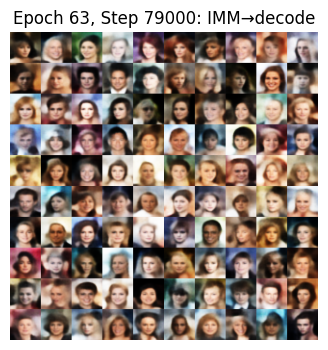

[Epoch 63/80  Step 79200]  Reconstruction=0.01856  MMD=0.04518 IMM=0.00860
[Epoch 63/80  Step 79400]  Reconstruction=0.01895  MMD=0.04570 IMM=-0.00154
[Epoch 63/80  Step 79600]  Reconstruction=0.02060  MMD=0.02826 IMM=0.00618
[Epoch 63/80  Step 79800]  Reconstruction=0.01927  MMD=0.02559 IMM=0.00769
[Epoch 63/80  Step 80000]  Reconstruction=0.01844  MMD=0.02011 IMM=0.00508


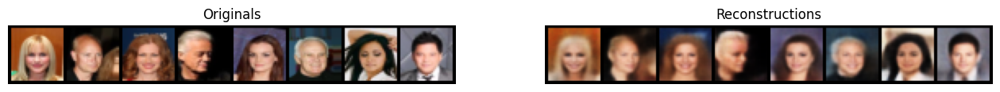

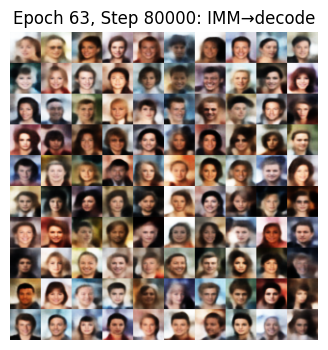

[Epoch 64/80  Step 80200]  Reconstruction=0.02037  MMD=0.02734 IMM=0.00190
[Epoch 64/80  Step 80400]  Reconstruction=0.01846  MMD=0.05176 IMM=0.00736
[Epoch 64/80  Step 80600]  Reconstruction=0.01856  MMD=0.07704 IMM=0.01349
[Epoch 64/80  Step 80800]  Reconstruction=0.01857  MMD=0.02682 IMM=-0.02897
[Epoch 64/80  Step 81000]  Reconstruction=0.02079  MMD=0.04292 IMM=-0.01736


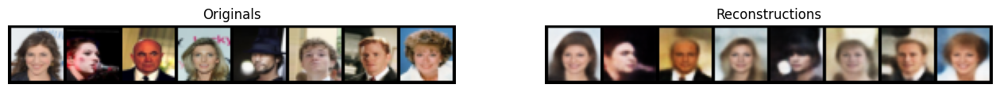

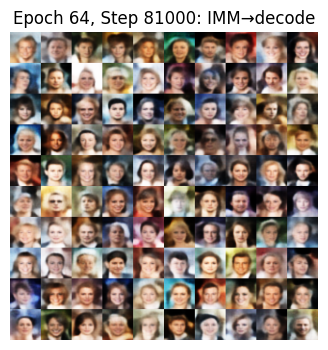

[Epoch 64/80  Step 81200]  Reconstruction=0.01979  MMD=0.04461 IMM=0.01233
[Epoch 65/80  Step 81400]  Reconstruction=0.01891  MMD=0.06572 IMM=-0.00339
[Epoch 65/80  Step 81600]  Reconstruction=0.01929  MMD=0.04524 IMM=-0.03670
[Epoch 65/80  Step 81800]  Reconstruction=0.02116  MMD=0.02359 IMM=0.01937
[Epoch 65/80  Step 82000]  Reconstruction=0.01927  MMD=0.01789 IMM=-0.00189


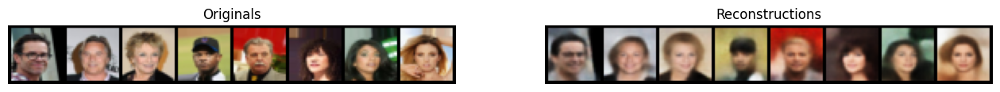

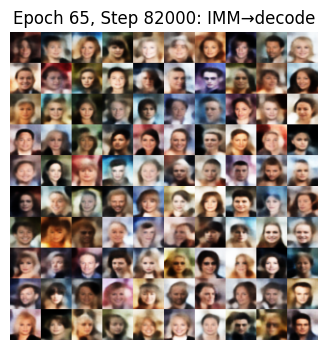

[Epoch 65/80  Step 82200]  Reconstruction=0.01987  MMD=0.03602 IMM=-0.04619
[Epoch 65/80  Step 82400]  Reconstruction=0.01995  MMD=0.04888 IMM=0.00575
[Epoch 65/80  Step 82600]  Reconstruction=0.02012  MMD=0.02565 IMM=-0.01241
[Epoch 66/80  Step 82800]  Reconstruction=0.02060  MMD=0.02179 IMM=0.00767
[Epoch 66/80  Step 83000]  Reconstruction=0.01986  MMD=0.02719 IMM=-0.00258


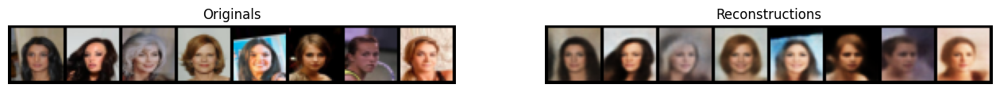

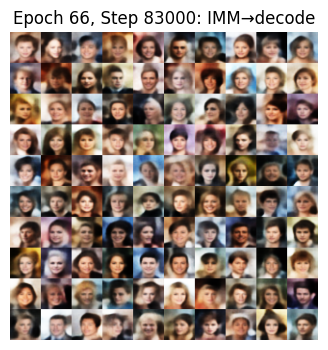

[Epoch 66/80  Step 83200]  Reconstruction=0.01861  MMD=0.04512 IMM=0.00272
[Epoch 66/80  Step 83400]  Reconstruction=0.01826  MMD=0.02597 IMM=0.00187
[Epoch 66/80  Step 83600]  Reconstruction=0.01982  MMD=0.04117 IMM=-0.03112
[Epoch 66/80  Step 83800]  Reconstruction=0.02038  MMD=0.03884 IMM=0.01256
[Epoch 67/80  Step 84000]  Reconstruction=0.01837  MMD=0.03347 IMM=0.00689


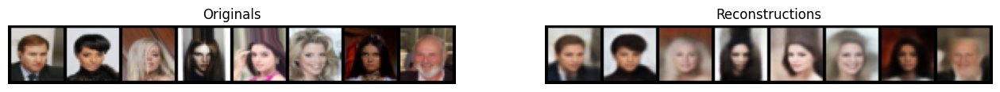

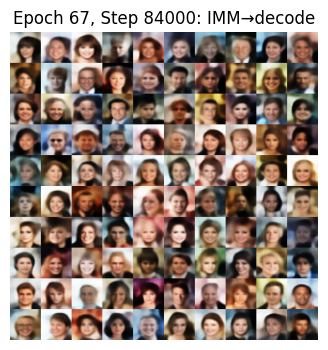

[Epoch 67/80  Step 84200]  Reconstruction=0.02107  MMD=0.03697 IMM=-0.01290
[Epoch 67/80  Step 84400]  Reconstruction=0.01867  MMD=0.02569 IMM=-0.00342
[Epoch 67/80  Step 84600]  Reconstruction=0.02043  MMD=0.02317 IMM=0.00320
[Epoch 67/80  Step 84800]  Reconstruction=0.01763  MMD=0.03577 IMM=0.00672
[Epoch 67/80  Step 85000]  Reconstruction=0.01911  MMD=0.02900 IMM=0.01887


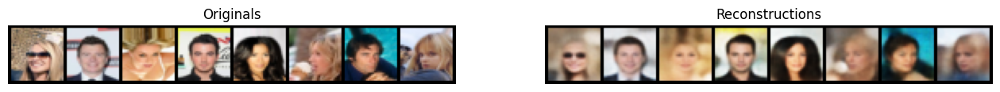

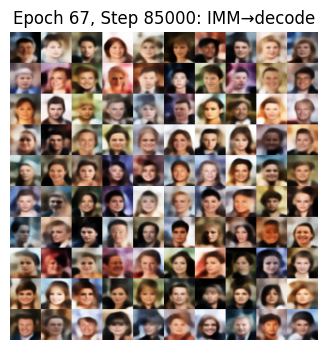

[Epoch 68/80  Step 85200]  Reconstruction=0.01956  MMD=0.02716 IMM=-0.02489
[Epoch 68/80  Step 85400]  Reconstruction=0.01998  MMD=0.02347 IMM=-0.00860
[Epoch 68/80  Step 85600]  Reconstruction=0.01923  MMD=0.03307 IMM=-0.00340
[Epoch 68/80  Step 85800]  Reconstruction=0.02049  MMD=0.03400 IMM=-0.00179
[Epoch 68/80  Step 86000]  Reconstruction=0.02017  MMD=0.02237 IMM=0.00668


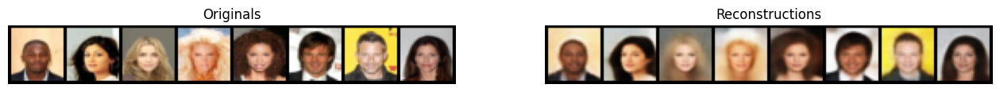

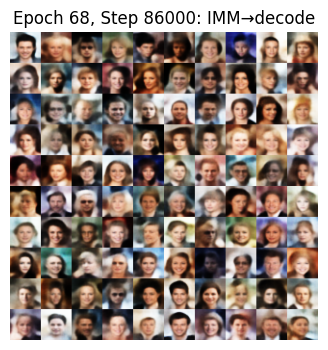

[Epoch 68/80  Step 86200]  Reconstruction=0.02049  MMD=0.03223 IMM=0.00392
[Epoch 68/80  Step 86400]  Reconstruction=0.01983  MMD=0.06000 IMM=-0.03113
[Epoch 69/80  Step 86600]  Reconstruction=0.01890  MMD=0.01899 IMM=-0.01259
[Epoch 69/80  Step 86800]  Reconstruction=0.01897  MMD=0.08628 IMM=-0.00084
[Epoch 69/80  Step 87000]  Reconstruction=0.01875  MMD=0.02530 IMM=0.01730


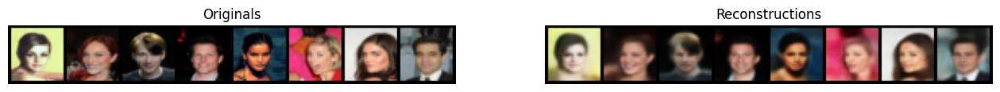

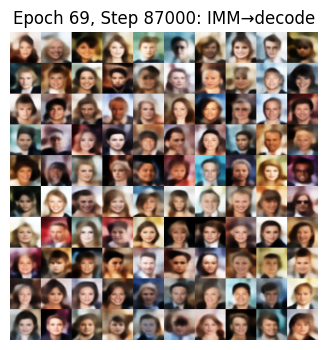

[Epoch 69/80  Step 87200]  Reconstruction=0.01966  MMD=0.03379 IMM=-0.00080
[Epoch 69/80  Step 87400]  Reconstruction=0.02013  MMD=0.03504 IMM=0.01868
[Epoch 69/80  Step 87600]  Reconstruction=0.01884  MMD=0.02537 IMM=0.00885
[Epoch 70/80  Step 87800]  Reconstruction=0.01877  MMD=0.03516 IMM=0.00336
[Epoch 70/80  Step 88000]  Reconstruction=0.01984  MMD=0.02628 IMM=0.00771


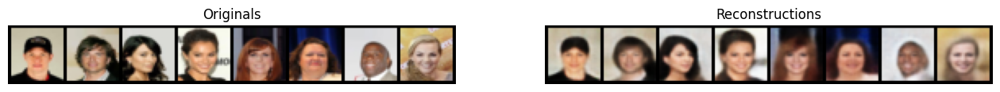

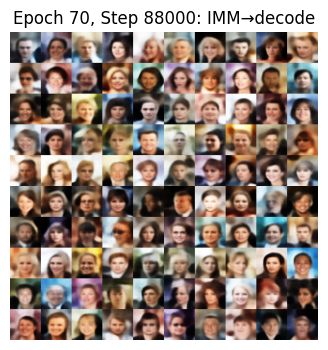

[Epoch 70/80  Step 88200]  Reconstruction=0.01896  MMD=0.03694 IMM=-0.01152
[Epoch 70/80  Step 88400]  Reconstruction=0.01816  MMD=0.02309 IMM=0.00650
[Epoch 70/80  Step 88600]  Reconstruction=0.01915  MMD=0.02227 IMM=0.00987
[Epoch 70/80  Step 88800]  Reconstruction=0.02034  MMD=0.01953 IMM=0.00162
[Epoch 71/80  Step 89000]  Reconstruction=0.02113  MMD=0.02010 IMM=0.01237


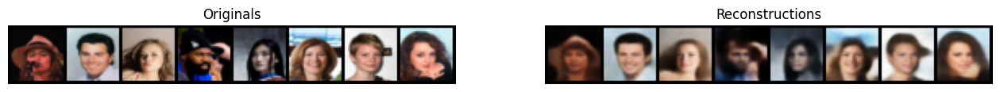

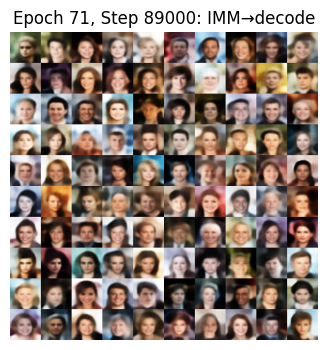

[Epoch 71/80  Step 89200]  Reconstruction=0.02060  MMD=0.02614 IMM=-0.00066
[Epoch 71/80  Step 89400]  Reconstruction=0.01873  MMD=0.03583 IMM=0.00995
[Epoch 71/80  Step 89600]  Reconstruction=0.01968  MMD=0.02751 IMM=0.00397
[Epoch 71/80  Step 89800]  Reconstruction=0.01853  MMD=0.03598 IMM=0.00137
[Epoch 71/80  Step 90000]  Reconstruction=0.01882  MMD=0.02009 IMM=0.00118


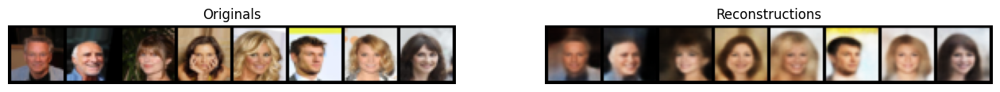

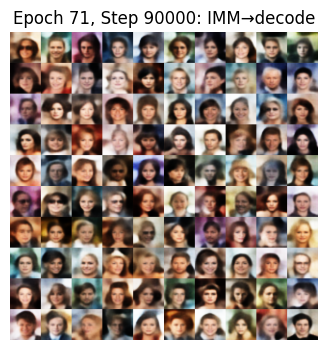

[Epoch 71/80  Step 90200]  Reconstruction=0.01970  MMD=0.02001 IMM=0.00292
[Epoch 72/80  Step 90400]  Reconstruction=0.01966  MMD=0.02555 IMM=-0.02963
[Epoch 72/80  Step 90600]  Reconstruction=0.02128  MMD=0.05239 IMM=0.00538
[Epoch 72/80  Step 90800]  Reconstruction=0.01944  MMD=0.03591 IMM=0.00961
[Epoch 72/80  Step 91000]  Reconstruction=0.01812  MMD=0.02582 IMM=0.01070


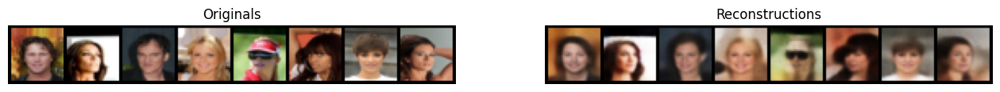

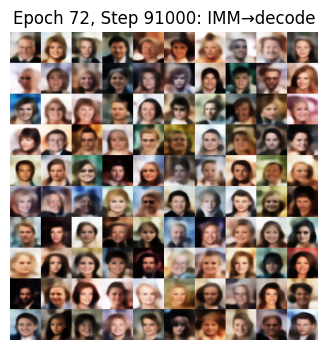

[Epoch 72/80  Step 91200]  Reconstruction=0.01949  MMD=0.02120 IMM=-0.02411
[Epoch 72/80  Step 91400]  Reconstruction=0.01997  MMD=0.03659 IMM=0.01206
[Epoch 73/80  Step 91600]  Reconstruction=0.02096  MMD=0.02479 IMM=-0.01462
[Epoch 73/80  Step 91800]  Reconstruction=0.01885  MMD=0.02147 IMM=0.00597
[Epoch 73/80  Step 92000]  Reconstruction=0.01931  MMD=0.03355 IMM=0.00043


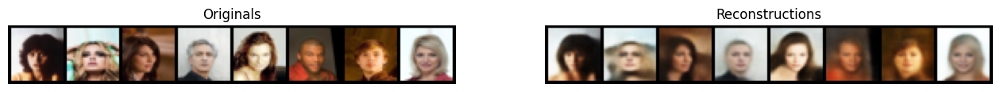

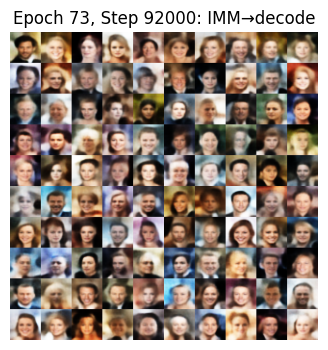

[Epoch 73/80  Step 92200]  Reconstruction=0.01900  MMD=0.04813 IMM=0.00563
[Epoch 73/80  Step 92400]  Reconstruction=0.01831  MMD=0.01748 IMM=0.01382
[Epoch 73/80  Step 92600]  Reconstruction=0.01918  MMD=0.09121 IMM=-0.00524
[Epoch 74/80  Step 92800]  Reconstruction=0.01967  MMD=0.04059 IMM=-0.02493
[Epoch 74/80  Step 93000]  Reconstruction=0.01841  MMD=0.02895 IMM=-0.00044


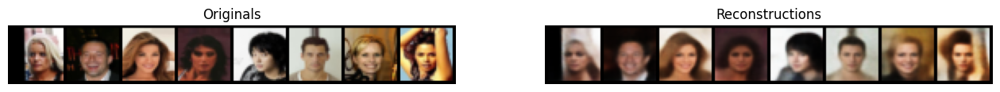

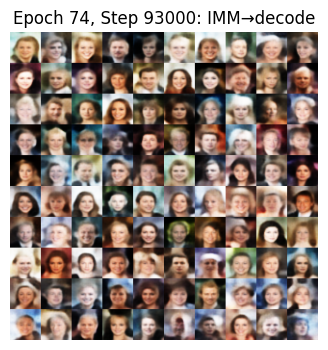

[Epoch 74/80  Step 93200]  Reconstruction=0.01955  MMD=0.02003 IMM=0.00624
[Epoch 74/80  Step 93400]  Reconstruction=0.01824  MMD=0.05001 IMM=0.00835
[Epoch 74/80  Step 93600]  Reconstruction=0.01898  MMD=0.05999 IMM=-0.01184
[Epoch 74/80  Step 93800]  Reconstruction=0.01791  MMD=0.02211 IMM=0.00025
[Epoch 74/80  Step 94000]  Reconstruction=0.01913  MMD=0.02755 IMM=0.00124


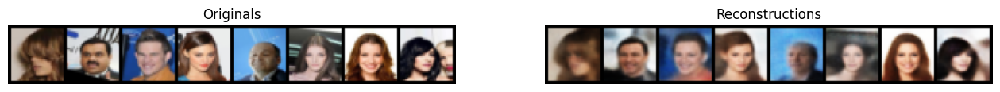

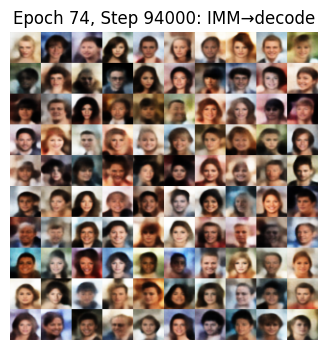

[Epoch 75/80  Step 94200]  Reconstruction=0.01911  MMD=0.02603 IMM=-0.01888
[Epoch 75/80  Step 94400]  Reconstruction=0.01959  MMD=0.02524 IMM=0.00254
[Epoch 75/80  Step 94600]  Reconstruction=0.01971  MMD=0.02664 IMM=0.01335
[Epoch 75/80  Step 94800]  Reconstruction=0.01861  MMD=0.02461 IMM=0.00283
[Epoch 75/80  Step 95000]  Reconstruction=0.01945  MMD=0.03051 IMM=-0.01206


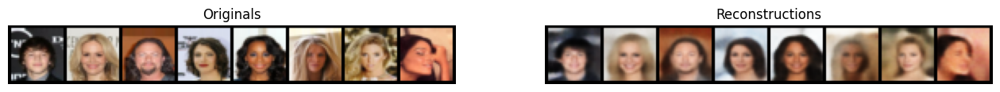

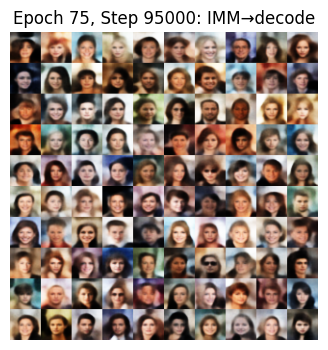

[Epoch 75/80  Step 95200]  Reconstruction=0.02047  MMD=0.02738 IMM=0.00334
[Epoch 76/80  Step 95400]  Reconstruction=0.01948  MMD=0.03420 IMM=0.00228
[Epoch 76/80  Step 95600]  Reconstruction=0.01979  MMD=0.02484 IMM=0.00112
[Epoch 76/80  Step 95800]  Reconstruction=0.01858  MMD=0.01900 IMM=-0.01456
[Epoch 76/80  Step 96000]  Reconstruction=0.01859  MMD=0.02719 IMM=-0.00021


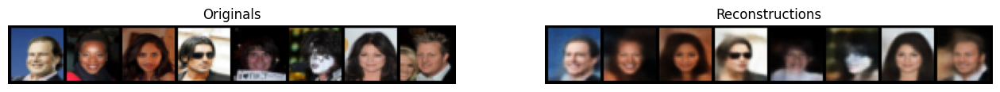

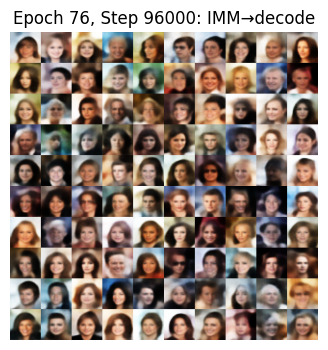

[Epoch 76/80  Step 96200]  Reconstruction=0.02057  MMD=0.01627 IMM=0.00876
[Epoch 76/80  Step 96400]  Reconstruction=0.01953  MMD=0.02096 IMM=0.00669
[Epoch 77/80  Step 96600]  Reconstruction=0.01648  MMD=0.03010 IMM=-0.02665
[Epoch 77/80  Step 96800]  Reconstruction=0.01987  MMD=0.02242 IMM=-0.02628
[Epoch 77/80  Step 97000]  Reconstruction=0.01960  MMD=0.02424 IMM=0.00553


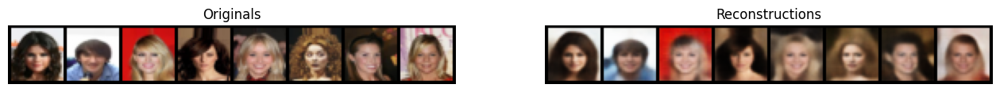

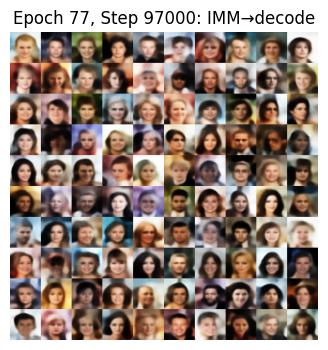

[Epoch 77/80  Step 97200]  Reconstruction=0.01954  MMD=0.02383 IMM=0.00702
[Epoch 77/80  Step 97400]  Reconstruction=0.01859  MMD=0.01972 IMM=0.00053
[Epoch 77/80  Step 97600]  Reconstruction=0.02016  MMD=0.02684 IMM=0.00405
[Epoch 77/80  Step 97800]  Reconstruction=0.01852  MMD=0.02257 IMM=0.01475
[Epoch 78/80  Step 98000]  Reconstruction=0.01884  MMD=0.01987 IMM=-0.02340


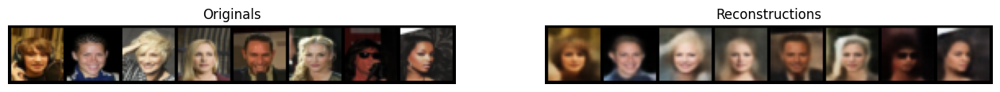

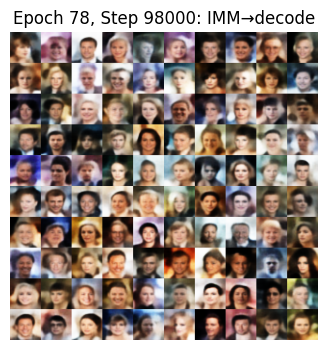

[Epoch 78/80  Step 98200]  Reconstruction=0.01854  MMD=0.02634 IMM=0.00916
[Epoch 78/80  Step 98400]  Reconstruction=0.02004  MMD=0.02051 IMM=0.00467
[Epoch 78/80  Step 98600]  Reconstruction=0.01964  MMD=0.02343 IMM=-0.06064
[Epoch 78/80  Step 98800]  Reconstruction=0.01983  MMD=0.04097 IMM=-0.00419
[Epoch 78/80  Step 99000]  Reconstruction=0.02036  MMD=0.04110 IMM=0.00373


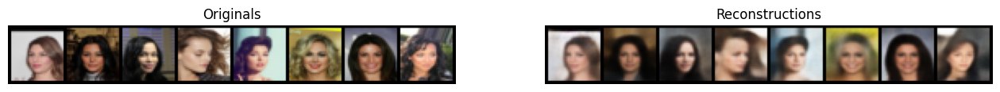

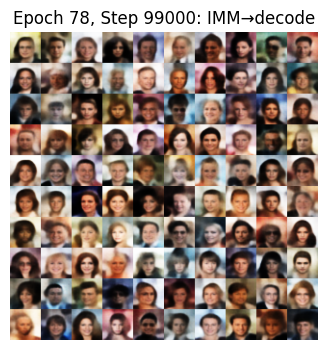

[Epoch 79/80  Step 99200]  Reconstruction=0.01977  MMD=0.01747 IMM=0.00379
[Epoch 79/80  Step 99400]  Reconstruction=0.02005  MMD=0.03118 IMM=0.00943
[Epoch 79/80  Step 99600]  Reconstruction=0.01831  MMD=0.02317 IMM=0.00466
[Epoch 79/80  Step 99800]  Reconstruction=0.02139  MMD=0.03471 IMM=0.00751
[Epoch 79/80  Step 100000]  Reconstruction=0.02092  MMD=0.02095 IMM=0.00426


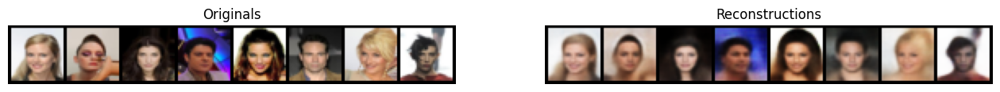

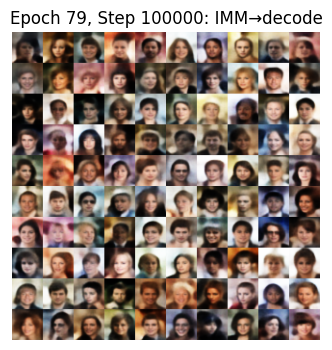

[Epoch 79/80  Step 100200]  Reconstruction=0.01851  MMD=0.04772 IMM=0.00349
[Epoch 79/80  Step 100400]  Reconstruction=0.01828  MMD=0.03873 IMM=-0.02251
[Epoch 80/80  Step 100600]  Reconstruction=0.01980  MMD=0.03460 IMM=0.00817
[Epoch 80/80  Step 100800]  Reconstruction=0.02024  MMD=0.04236 IMM=0.00543
[Epoch 80/80  Step 101000]  Reconstruction=0.01786  MMD=0.02521 IMM=-0.02927


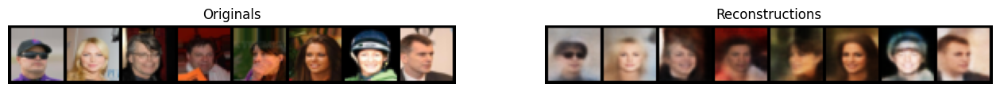

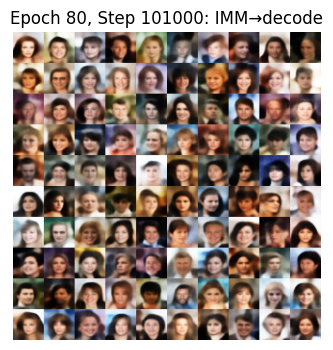

[Epoch 80/80  Step 101200]  Reconstruction=0.02031  MMD=0.03132 IMM=0.01326
[Epoch 80/80  Step 101400]  Reconstruction=0.01946  MMD=0.02316 IMM=-0.00717
[Epoch 80/80  Step 101600]  Reconstruction=0.01909  MMD=0.03147 IMM=0.00748


In [ ]:
# ────────────────────────────────────────────────────────────────
# 1) Install / import dependencies
# (Colab already comes with torch, torchvision, etc.)
# ────────────────────────────────────────────────────────────────
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.autograd import Variable
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.datasets import CelebA
import torchvision
import numpy as np
import matplotlib.pyplot as plt
import math
import random
import os
#%pip install gdown

from tqdm import tqdm

def set_seed(seed: int):
    # 1) Python built-ins
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

    # 2) NumPy
    np.random.seed(seed)

    # 3) Torch (CPU & GPU)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    # 4) Torch determinism flags
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark     = False

    # 5) (Optional, PyTorch ≥1.8) enforce everywhere
    torch.use_deterministic_algorithms(True)

# ────────────────────────────────────────────────────────────────
# 2) “Flatten” and “Reshape” helpers (for Conv ↔ FC transitions)
# ────────────────────────────────────────────────────────────────
class Flatten(nn.Module):
    def forward(self, x):
        return x.view(x.size(0), -1)

class Reshape(nn.Module):
    def __init__(self, outer_shape):
        super().__init__()
        self.outer_shape = outer_shape
    def forward(self, x):
        return x.view(x.size(0), *self.outer_shape)

# ────────────────────────────────────────────────────────────────
# 3) Encoder / Decoder (DC-GAN style) exactly as in the original
# ────────────────────────────────────────────────────────────────
class Encoder(nn.Module):
    def __init__(
        self,
        img_channels:    int,  # e.g. 3
        filters:         int,  # base filter count, e.g. 64
        num_conv:        int,  # conv kernel size, e.g. 3
        intermediate_dim:int,  # size of FC before latent heads, e.g. 512
        latent_dim:      int,  # size of z, e.g. 128
        img_rows:        int,  # CIFAR height, 32
        img_cols:        int,  # CIFAR width,  32
    ):
        super().__init__()
        pad = num_conv // 2

        # 32→16→8→4 with stride=2
        self.conv1 = nn.Conv2d(img_channels, filters,     num_conv, stride=2, padding=pad)
        self.bn1   = nn.BatchNorm2d(filters)
        self.conv2 = nn.Conv2d(filters,      filters*2,  num_conv, stride=2, padding=pad)
        self.bn2   = nn.BatchNorm2d(filters*2)
        self.conv3 = nn.Conv2d(filters*2,    filters*4,  num_conv, stride=2, padding=pad)
        self.bn3   = nn.BatchNorm2d(filters*4)
        self.act   = nn.ReLU(inplace=True)

        # compute flatten size: (filters*4) × 4 × 4
        down = 2**3  # three halving steps
        h, w = img_rows // down, img_cols // down
        flat_dim = filters*4 * h * w

        # FC → intermediate, then two heads
        self.flatten   = nn.Flatten()
        self.fc_shared = nn.Linear(flat_dim, intermediate_dim)
        self.fc_mu     = nn.Linear(intermediate_dim, latent_dim)
        self.fc_logvar = nn.Linear(intermediate_dim, latent_dim)

    def forward(self, x):
        x = self.act(self.bn1(self.conv1(x)))  # [B, F, 16,16]
        x = self.act(self.bn2(self.conv2(x)))  # [B,2F, 8, 8]
        x = self.act(self.bn3(self.conv3(x)))  # [B,4F, 4, 4]
        x = self.flatten(x)                    # [B, 4F*4*4]
        h = self.act(self.fc_shared(x))        # [B, intermediate_dim]
        return self.fc_mu(h), self.fc_logvar(h)


class Decoder(nn.Module):
    def __init__(
        self,
        img_channels:    int,
        filters:         int,
        num_conv:        int,  # not used for deconv here
        intermediate_dim:int,
        latent_dim:      int,
        img_rows:        int,
        img_cols:        int,
    ):
        super().__init__()
        down = 2**3
        h, w = img_rows // down, img_cols // down
        # project z → (filters*4) × 4 × 4
        self.fc1 = nn.Linear(latent_dim, intermediate_dim)
        self.fc2 = nn.Linear(intermediate_dim, filters*4 * h * w)
        self.act = nn.ReLU(inplace=True)
        self.reshape = lambda z: z.view(-1, filters*4, h, w)

        # upsample 4→8→16→32 with 4×4 kernels, stride=2, padding=1
        self.deconv1 = nn.ConvTranspose2d(filters*4, filters*2, 4, 2, 1)
        self.bn1      = nn.BatchNorm2d(filters*2)
        self.deconv2 = nn.ConvTranspose2d(filters*2, filters,   4, 2, 1)
        self.bn2      = nn.BatchNorm2d(filters)
        self.deconv3 = nn.ConvTranspose2d(filters,    img_channels, 4, 2, 1)
        self.out_act = nn.Sigmoid()  # outputs in [0,1]
        self.out_act = nn.Tanh()  # outputs in [-1,1] (as per CelebA normalization)

    def forward(self, z):
        h = self.act(self.fc1(z))            # [B, intermediate_dim]
        h = self.act(self.fc2(h))            # [B, 4F*h*w]
        h = self.reshape(h)                  # [B,4F,4,4]
        h = self.act(self.bn1(self.deconv1(h)))  # [B,2F,8,8]
        h = self.act(self.bn2(self.deconv2(h)))  # [B, F,16,16]
        h = self.out_act(self.deconv3(h))       # [B,3,32,32]
        return h

# ────────────────────────────────────────────────────────────────
# 4) MMD computation (RBF kernel)
# ────────────────────────────────────────────────────────────────
def compute_kernel(x, y):
    x_size, y_size, dim = x.size(0), y.size(0), x.size(1)
    x_exp = x.unsqueeze(1).expand(x_size, y_size, dim)
    y_exp = y.unsqueeze(0).expand(x_size, y_size, dim)
    kernel_input = ((x_exp - y_exp)**2).mean(2) / float(dim)
    return torch.exp(-kernel_input)  # [x_size, y_size]

def compute_mmd(x, y):
    x_kernel = compute_kernel(x, x).mean()
    y_kernel = compute_kernel(y, y).mean()
    xy_kernel = compute_kernel(x, y).mean()
    return x_kernel + y_kernel - 2*xy_kernel

# ────────────────────────────────────────────────────────────────
# 5) The “pure” VAE (no KL, only MMD) wrapper
# ────────────────────────────────────────────────────────────────
class Model(nn.Module):
    def __init__(self,
                 img_channels:     3,
                 filters:          32,
                 num_conv:         3,
                 intermediate_dim: 128,
                 z_dim:       2,
                 img_rows:         32,
                 img_cols:         32):
        super().__init__()
        # ← the order here must match your Encoder’s __init__
        self.encoder = Encoder(
            img_channels=img_channels,
            filters=filters,
            num_conv=num_conv,
            intermediate_dim=intermediate_dim,
            latent_dim=z_dim,
            img_rows=img_rows,
            img_cols=img_cols,
        )
        self.decoder = Decoder(
            img_channels=img_channels,
            filters=filters,
            num_conv=num_conv,
            intermediate_dim=intermediate_dim,
            latent_dim=z_dim,
            img_rows=img_rows,
            img_cols=img_cols,
        )

    def reparameterize(self, mu: torch.Tensor, logvar: torch.Tensor) -> torch.Tensor:
        # Optionally clamp logvar for stability
        logvar = torch.clamp(logvar, min=-10.0, max=10.0)
        std = (0.5 * logvar).exp()
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x: torch.Tensor):
        mu, logvar = self.encoder(x)
        z = self.reparameterize(mu, logvar)
        x_recon = self.decoder(z)
        return z, x_recon
# ────────────────────────────────────────────────────────────────
# 6) IMM schedule and parameterizations (OTFM Euler-FM version)
# ────────────────────────────────────────────────────────────────
class IMMSchedule(nn.Module):
    def alpha(self, t: torch.Tensor) -> torch.Tensor:
        raise NotImplementedError
    def sigma(self, t: torch.Tensor) -> torch.Tensor:
        raise NotImplementedError
    def lamb(self, t: torch.Tensor) -> torch.Tensor:
        raise NotImplementedError
    def lamb_diff(self, t: torch.Tensor) -> torch.Tensor:
        raise NotImplementedError
    def eta(self, t: torch.Tensor) -> torch.Tensor:
        raise NotImplementedError
    def eta_inv(self, u: torch.Tensor) -> torch.Tensor:
        raise NotImplementedError

class CosineSchedule(IMMSchedule):
    @property
    def tmax(self):
        return 0.996

    @property
    def tmin(self):
        return 0.001

    def alpha(self, t: torch.Tensor) -> torch.Tensor:
        return torch.cos(0.5 * math.pi * t)

    def sigma(self, t: torch.Tensor) -> torch.Tensor:
        return torch.sin(0.5 * math.pi * t)

    def lamb(self, t: torch.Tensor) -> torch.Tensor:
        return 2.0 * torch.log(1.0 / torch.tan(0.5 * math.pi * t))

    def lamb_diff(self, t: torch.Tensor) -> torch.Tensor:
        return -2.0 / torch.sin(math.pi * t)

    def eta(self, t: torch.Tensor) -> torch.Tensor:
        return torch.tan(0.5 * math.pi * t)

    def eta_inv(self, u: torch.Tensor) -> torch.Tensor:
        return 2.0 * torch.atan(u) / math.pi

class OTFMSchedule(IMMSchedule):
    @property
    def tmax(self):
        return 0.994
    @property
    def tmin(self):
        return 0.001

    def alpha(self, t: torch.Tensor) -> torch.Tensor:
        return 1.0 - t
    def sigma(self, t: torch.Tensor) -> torch.Tensor:
        return t
    def lamb(self, t: torch.Tensor) -> torch.Tensor:
        return 2.0 * torch.log((1.0 - t) / t)
    def lamb_diff(self, t: torch.Tensor) -> torch.Tensor:
        return 2.0 / (t*t - t)
    def eta(self, t: torch.Tensor) -> torch.Tensor:
        return t / (1.0 - t)
    def eta_inv(self, u: torch.Tensor) -> torch.Tensor:
        return u / (u + 1.0)

class IMMParameterization(nn.Module):
    def __init__(self, sigma_data: float, schedule: IMMSchedule):
        super().__init__()
        self.sigma_data = sigma_data
        self.schedule = schedule

    def c_noise(self, t: torch.Tensor) -> torch.Tensor:
        return 1000.0 * t

    def c_in(self, t: torch.Tensor) -> torch.Tensor:
        a = self.schedule.alpha(t)
        s = self.schedule.sigma(t)
        return 1.0 / (self.sigma_data * torch.sqrt(a*a + s*s))

    def c_skip(self, s: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        raise NotImplementedError
    def c_out(self, s: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        raise NotImplementedError

class OtFmEulerFmParameterization(IMMParameterization):
    def __init__(self, sigma_data: float):
        super().__init__(sigma_data, OTFMSchedule())

    def c_skip(self, s: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        # always 1
        return torch.ones_like(s)

    def c_out(self, s: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        # -(t - s) * sigma_data
        return -(t - s) * self.sigma_data

class OtFmIdentityParameterization(IMMParameterization):
    def __init__(self, sigma_data: float):
        super().__init__(sigma_data, OTFMSchedule())

    def c_skip(self, s: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        # sigma_s / sigma_t
        σ_s = self.schedule.sigma(s)
        σ_t = self.schedule.sigma(t)
        return σ_s / σ_t

    def c_out(self, s: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        # alpha_s − alpha_t * (σ_s/σ_t)
        α_s = self.schedule.alpha(s)
        α_t = self.schedule.alpha(t)
        σ_s = self.schedule.sigma(s)
        σ_t = self.schedule.sigma(t)
        return α_s - α_t * (σ_s / σ_t)

class CosineIdentityParameterization(IMMParameterization):
    def __init__(self, sigma_data: float):
        super().__init__(sigma_data, CosineSchedule())

    def c_skip(self, s: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        sigma_s = self.schedule.sigma(s)
        sigma_t = self.schedule.sigma(t)
        return sigma_s / sigma_t

    def c_out(self, s: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        alpha_s = self.schedule.alpha(s)
        alpha_t = self.schedule.alpha(t)
        sigma_s = self.schedule.sigma(s)
        sigma_t = self.schedule.sigma(t)
        return alpha_s - alpha_t * sigma_s / sigma_t

class CosineSimpleEDMParameterization(IMMParameterization):
    def __init__(self, sigma_data: float):
        # uses the CosineSchedule defined above
        super().__init__(sigma_data, CosineSchedule())

    def c_skip(self, s: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        # cos(½π (t−s))
        return torch.cos(0.5 * math.pi * (t - s))

    def c_out(self, s: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        # − sin(½π (t−s)) · σ_data
        return -torch.sin(0.5 * math.pi * (t - s)) * self.sigma_data

class OtFmSimpleEDMParameterization(IMMParameterization):
    def __init__(self, sigma_data: float):
        # uses the Linear OTFM schedule defined above
        super().__init__(sigma_data, OTFMSchedule())

    def c_skip(self, s: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        a_s = self.schedule.alpha(s)
        a_t = self.schedule.alpha(t)
        σ_s = self.schedule.sigma(s)
        σ_t = self.schedule.sigma(t)
        # (a_s a_t + σ_s σ_t) / (a_t² + σ_t²)
        return (a_s * a_t + σ_s * σ_t) / (a_t**2 + σ_t**2)

    def c_out(self, s: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        a_s = self.schedule.alpha(s)
        a_t = self.schedule.alpha(t)
        σ_s = self.schedule.sigma(s)
        σ_t = self.schedule.sigma(t)
        # −(a_s σ_t − σ_s a_t) / √(a_t² + σ_t²)  · σ_data
        return -(a_s*σ_t - σ_s*a_t) / torch.sqrt(a_t**2 + σ_t**2) * self.sigma_data

# ────────────────────────────────────────────────────────────────
# 7) Small MLP builder to feed (x_t * c_in(t), c_noise(s), c_noise(t)) → D
# ────────────────────────────────────────────────────────────────
def get_mlp(hidden_dim: int, n_hidden: int, input_dim: int, output_dim: int) -> nn.Module:
    layers = []
    in_dim = input_dim
    for _ in range(n_hidden):
        layers.append(nn.Linear(in_dim, hidden_dim))
        layers.append(nn.Mish())
        in_dim = hidden_dim
    layers.append(nn.Linear(hidden_dim, output_dim))
    return nn.Sequential(*layers)

class ResBlock(nn.Module):
    """A single residual block: LayerNorm → Linear → SiLU → Linear → skip."""
    def __init__(self, dim):
        super().__init__()
        self.norm = nn.LayerNorm(dim)
        self.fc1  = nn.Linear(dim, dim * 2)
        self.fc2  = nn.Linear(dim * 2, dim)
        self.act  = nn.SiLU()

    def forward(self, x):
        h = self.norm(x)
        h = self.act(self.fc1(h))
        h = self.fc2(h)
        return x + h

class ResidualDenoiser(nn.Module):
    """
    Residual MLP denoiser for IMM.

    Input:  [B, D+2]  →  project up
    Middle: N × ResBlock(dim)
    Output: project back to [B, D]
    """
    def __init__(self,
                 input_dim:  int,
                 model_dim:  int = 1024,
                 n_blocks:   int = 8,
                 output_dim: int = None):
        super().__init__()
        output_dim = output_dim or (input_dim - 2)  # D = input_dim-2
        # initial projection
        self.project_in  = nn.Sequential(
            nn.Linear(input_dim, model_dim),
            nn.SiLU()
        )
        # residual blocks
        self.blocks = nn.ModuleList([ResBlock(model_dim) for _ in range(n_blocks)])
        # final projection
        self.project_out = nn.Sequential(
            nn.LayerNorm(model_dim),
            nn.SiLU(),
            nn.Linear(model_dim, output_dim)
        )

    def forward(self, x):
        # x: [B, D+2]
        h = self.project_in(x)           # [B, model_dim]
        for block in self.blocks:
            h = block(h)                 # [B, model_dim]
        return self.project_out(h)       # [B, D]

# ────────────────────────────────────────────────────────────────
# 8) The IMM model (general latent‐dimension D = z_dim)
# ────────────────────────────────────────────────────────────────
class IMM(nn.Module):
    def __init__(self,
                 network: nn.Module,
                 parameterization: IMMParameterization,
                 a: int = 1,
                 b: int = 4,
                 eta_max: float = 160.0,
                 eta_min: float = 1e-8,
                 k: int = 12,
                 M: int = 16,
                 D: int = 2):
        """
        network: a small MLP mapping R^(D+2) → R^D
        parameterization: e.g. OtFmEulerFmParameterization(sigma_data)
        a, b, eta_max, eta_min, k, M: hyperparams
        D: latent dimension (e.g. 2 or 32)
        """
        super().__init__()
        self.network = network
        self.parameterization = parameterization
        self.schedule = parameterization.schedule

        self.D = D
        self.a = a
        self.b = b
        self.eta_max = eta_max
        self.eta_min = eta_min
        self.k = k
        self.M = M

    def forward(self, x_t: torch.Tensor, s: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        # x_t: [B, D], s,t: [B,1]
        skip = self.parameterization.c_skip(s, t) * x_t  # [B, D]

        # Build model input = [ x_t * c_in(t), c_noise(s), c_noise(t) ]
        c_in_t = self.parameterization.c_in(t)       # [B, 1]
        x_scaled = x_t * c_in_t                       # [B, D]
        noise_s = self.parameterization.c_noise(s)    # [B, 1]
        noise_t = self.parameterization.c_noise(t)    # [B, 1]
        inp = torch.cat([x_scaled, noise_s, noise_t], dim=-1)  # [B, D+2]

        out = self.network(inp)                               # [B, D]
        out = self.parameterization.c_out(s, t) * out         # [B, D]
        return skip + out

    def _ddim(self,
              x_source: torch.Tensor,
              x_target: torch.Tensor,
              s: torch.Tensor,
              t: torch.Tensor) -> torch.Tensor:
        # x_source @ time t, x_target @ time 0 → produce x @ time s
        a_s = self.schedule.alpha(s)   # [B,1]
        a_t = self.schedule.alpha(t)   # [B,1]
        sig_s = self.schedule.sigma(s) # [B,1]
        sig_t = self.schedule.sigma(t) # [B,1]

        term1 = (a_s - (sig_s / sig_t) * a_t) * x_target    # [B, D]
        term2 = (sig_s / sig_t) * x_source                 # [B, D]
        return term1 + term2

    def _kernel(self,
                x: torch.Tensor,
                y: torch.Tensor,
                s: torch.Tensor,
                t: torch.Tensor) -> torch.Tensor:
        # Pairwise kernel between x and y at times s < t
        eps = 1e-8
        c_out_st = self.parameterization.c_out(s, t)           # [N,1]
        w = torch.abs(1.0 / (c_out_st + eps))                   # [N,1]

        diff = x - y                                           # [N, D]
        dist = torch.norm(diff, p=2, dim=-1).clamp(min=eps)     # [N,]
        w_flat = w.view_as(dist)                               # [N,]
        log_k = -w_flat * dist / float(self.D)                  # [N,]

        mask = (t.view(-1) > s.view(-1))                        # [N,]
        return torch.where(mask, torch.exp(log_k), torch.zeros_like(log_k))  # [N,]

    def _kernel_for_diff(self,
                         difference: torch.Tensor,
                         s: torch.Tensor,
                         t: torch.Tensor) -> torch.Tensor:
        zeros = torch.zeros_like(difference)
        return self._kernel(difference, zeros, s.unsqueeze(-1), t.unsqueeze(-1))

    def _weight_fn(self, s: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        # s,t: [N,1]
        t_flat = t.view(-1)                             # [N,]
        a_t = self.schedule.alpha(t).view(-1)           # [N,]
        sig_t = self.schedule.sigma(t).view(-1)         # [N,]
        logSNR_t = self.schedule.lamb(t).view(-1)       # [N,]
        dlogSNR_t = self.schedule.lamb_diff(t).view(-1) # [N,]

        coef = 0.5 * torch.sigmoid(self.b - logSNR_t) * (-dlogSNR_t)  # [N,]
        denom = a_t.pow(2) + sig_t.pow(2)                              # [N,]
        num = a_t.pow(self.a)                                         # [N,]
        return coef * num / denom                                     # [N,]

    def _map_fn(self, s: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        eps = (self.eta_max - self.eta_min) / (2 ** self.k)
        eta_t = self.schedule.eta(t)                 # [B,1]
        val = eta_t - eps
        inv = self.schedule.eta_inv(val)             # [B,1]
        return torch.maximum(s, inv)                  # [B,1]

    def compute_loss(self, x: torch.Tensor) -> torch.Tensor:
        """
        x: [B, D], B must be divisible by M
        returns: scalar joint IMM loss
        """
        B = x.shape[0]
        M = self.M
        assert B % M == 0, f"Batch size ({B}) not divisible by M ({M})"

        G = B // M  # number of groups
        # 1) sample z_prior ~ N(0, σ_data² I) at t=1
        z_prior = self.parameterization.sigma_data * torch.randn_like(x)

        # 2) sample t_single ∈ [tmin, tmax], s_single ∈ [tmin, t_single]
        t_range = self.schedule.tmax - self.schedule.tmin
        t_single = torch.rand((G, 1), device=x.device) * t_range + self.schedule.tmin  # [G,1]
        s_single = torch.rand((G, 1), device=x.device) * (t_single - self.schedule.tmin) + self.schedule.tmin  # [G,1]

        # 3) repeat each M‐times → [B,1]
        t = t_single.repeat_interleave(M, dim=0)  # [B,1]
        s = s_single.repeat_interleave(M, dim=0)  # [B,1]

        # 4) r = map_fn(s, t)
        r = self._map_fn(s, t)  # [B,1]

        # 5) x_t = ddim(z_prior, x, t, 1)
        one_t = torch.ones_like(t)           # [B,1]
        x_t = self._ddim(z_prior, x, t, one_t)  # [B, D]

        # 6) x_r = ddim(x_t, x, r, t)
        x_r = self._ddim(x_t, x, r, t)       # [B, D]

        # 7) f_x_t, f_x_r
        f_x_t = self.forward(x_t, s, t)      # [B, D]
        f_x_r = self.forward(x_r, s, r).detach()  # [B, D]

        # 8) reshape to [G, M, D]
        f_x_t = f_x_t.view(G, M, self.D)     # [G, M, D]
        f_x_r = f_x_r.view(G, M, self.D)     # [G, M, D]

        # 9) pairwise differences (G × M × M × D)
        diff1 = (f_x_t.unsqueeze(1) - f_x_t.unsqueeze(2)).reshape(G*M*M, self.D)
        diff2 = (f_x_r.unsqueeze(1) - f_x_r.unsqueeze(2)).reshape(G*M*M, self.D)
        diff3 = (f_x_t.unsqueeze(1) - f_x_r.unsqueeze(2)).reshape(G*M*M, self.D)

        # 10) build ss, ts, rs arrays of length G*M*M
        ss = s_single.repeat_interleave(M*M, dim=0).view(-1)  # [G*M*M,]
        ts = t_single.repeat_interleave(M*M, dim=0).view(-1)  # [G*M*M,]
        rs = self._map_fn(ss.unsqueeze(-1), ts.unsqueeze(-1)).view(-1)  # [G*M*M,]

        # 11) compute kernel terms
        term1 = self._kernel_for_diff(diff1, ss, ts)  # [G*M*M,]
        term2 = self._kernel_for_diff(diff2, ss, rs)  # [G*M*M,]
        term3 = -2.0 * self._kernel_for_diff(diff3, ss, ts)  # [G*M*M,]

        # 12) weights
        weights = self._weight_fn(ss.unsqueeze(-1), ts.unsqueeze(-1))  # [G*M*M,]

        joint = term1 + term2 + term3  # [G*M*M,]
        return torch.mean(joint * weights)

    def sample(self, n_samples: int, times: torch.Tensor) -> torch.Tensor:
        """
        times: 1D tensor in descending order, e.g. [1.0, 0.9, ..., tmin]
        returns: [n_samples, D] latents at t=tmin
        """
        device = next(self.parameters()).device
        x = self.parameterization.sigma_data * torch.randn((n_samples, self.D), device=device)
        for i in range(len(times) - 1):
            t_val = times[i]
            s_val = times[i+1]
            t_tensor = torch.full((n_samples, 1), t_val, device=device)
            s_tensor = torch.full((n_samples, 1), s_val, device=device)
            x = self.forward(x, s_tensor, t_tensor)
        return x  # [n_samples, D]

# ────────────────────────────────────────────────────────────────
# 9) Utility to tile [batch,28,28,1] → grid image
# ────────────────────────────────────────────────────────────────
def convert_to_display(samples: np.ndarray) -> np.ndarray:
    """
    Tile a batch of images into a square grid.
    samples: [B, H, W, C], B must be a perfect square.
    Returns: [H*grid, W*grid, C].
    """
    B, H, W, C = samples.shape
    cnt = int(math.sqrt(B))
    assert cnt*cnt == B, "batch size must be a perfect square"
    # first reshape into (grid_y, grid_x, H, W, C)
    grid = samples.reshape(cnt, cnt, H, W, C)
    # swap axes to (grid_y, H, grid_x, W, C)
    grid = grid.transpose(0, 2, 1, 3, 4)
    # merge to (grid_y*H, grid_x*W, C)
    grid = grid.reshape(cnt * H, cnt * W, C)
    return grid
# ────────────────────────────────────────────────────────────────
# 10) to visualize the reconstructed images
# ────────────────────────────────────────────────────────────────
# def show_reconstructions(model, dataloader, device, n=8):
#     """
#     Grab one batch from dataloader, run it through model,
#     and plot the first n originals vs reconstructions.
#     """
#     model.eval()
#     # grab a single batch
#     imgs, _ = next(iter(dataloader))
#     imgs = imgs.to(device)

#     # forward pass
#     with torch.no_grad():
#         z, recon = model(imgs)        # or: recon, mu, logvar = model(imgs)
#     # take first n
#     origs = imgs[:n]
#     recs  = recon[:n]

#     # make two image-grids
#     grid_orig = torchvision.utils.make_grid(origs.cpu(), nrow=n, normalize=True)
#     grid_recon= torchvision.utils.make_grid(recs.cpu(),  nrow=n, normalize=True)

#     # plot
#     plt.figure(figsize=(2*n,4))
#     plt.subplot(1,2,1)
#     plt.title("Originals")
#     plt.axis("off")
#     plt.imshow(np.transpose(grid_orig, (1,2,0)))
#     plt.subplot(1,2,2)
#     plt.title("Reconstructions")
#     plt.axis("off")
#     plt.imshow(np.transpose(grid_recon, (1,2,0)))
#     plt.show()

#     model.train()
def show_reconstructions(model, dataloader, device, n=8):
    """
    Grab one batch from dataloader, run it through model,
    and plot the first n originals vs reconstructions,
    denormalizing from [-1,1] → [0,1].
    """
    model.eval()
    # grab a single batch
    imgs, _ = next(iter(dataloader))
    imgs = imgs.to(device)

    # forward pass
    with torch.no_grad():
        z, recon = model(imgs)

    # take first n
    origs = imgs[:n].cpu()
    recs  = recon[:n].cpu()

    # undo Normalize(mean=0.5,std=0.5): x_denorm = x*0.5 + 0.5
    origs = origs * 0.5 + 0.5
    recs  = recs  * 0.5 + 0.5

    # clamp just in case of numerical overshoot
    origs = origs.clamp(0, 1)
    recs  = recs.clamp(0, 1)

    # make two image-grids (no internal normalization)
    grid_orig  = torchvision.utils.make_grid(origs, nrow=n)
    grid_recon = torchvision.utils.make_grid(recs,  nrow=n)

    # plot
    plt.figure(figsize=(2*n, 4))
    plt.subplot(1, 2, 1)
    plt.title("Originals")
    plt.axis("off")
    plt.imshow(np.transpose(grid_orig, (1, 2, 0)))
    plt.subplot(1, 2, 2)
    plt.title("Reconstructions")
    plt.axis("off")
    plt.imshow(np.transpose(grid_recon, (1, 2, 0)))
    plt.show()

    model.train()


# ────────────────────────────────────────────────────────────────
# 10) The combined “MMD + IMM” training loop
# ────────────────────────────────────────────────────────────────
def train(
    dataloader,
    z_dim=2,
    n_epochs=10,
    use_cuda=True,
    print_every=100,
    plot_every=500
):
    device = torch.device("cuda" if (torch.cuda.is_available() and use_cuda) else "cpu")
    print("Current CUDA device:", torch.cuda.current_device(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "n/a")

    # 10.1) Instantiate IMM (D = z_dim, M = 16)
    parametrization = OtFmEulerFmParameterization(sigma_data=1.0)
    #imm_net = get_mlp(hidden_dim=256, n_hidden=6, input_dim=z_dim+2, output_dim=z_dim).to(device)
    #imm_net = get_mlp(hidden_dim=2048, n_hidden=32, input_dim=z_dim+2, output_dim=z_dim)
    imm_net = ResidualDenoiser(input_dim = z_dim + 2, model_dim = 1024, n_blocks  = 8, output_dim= z_dim) #.to(device)
    imm_model = IMM(
        network=imm_net,
        parameterization=parametrization,
        a=1, b=4, eta_max=160.0, eta_min=1e-8, k=12, M=32,
        D=z_dim
    ).to(device)

    # 10.2) Instantiate the VAE (Encoder + Decoder)
    model = Model(3, 32, 3, 128, z_dim, 32, 32).to(device)

    # 10.3) Two optimizers: VAE params and IMM params
    optimizer_vae = torch.optim.Adam(model.parameters(), lr=1e-3)
    optimizer_imm = torch.optim.Adam(imm_model.parameters(), lr=1e-5)

    step_idx = 0
    for epoch in range(n_epochs):
        model.train()
        imm_model.train()

        for images, _labels in dataloader:
            step_idx += 1

            # ─── Zero gradients for both optimizers ───
            # optimizer_vae.zero_grad()
            # optimizer_imm.zero_grad()

            # ─── Move batch to device ───
            x = images.to(device)  # [B,1,28,28]

            # ─── Forward pass through VAE ───
            z, x_recon = model(x)  # z: [B, z_dim], x_recon: [B,1,28,28]
            z_det = z.detach()

            # (1) Reconstruction loss (MSE)
            nll = F.mse_loss(x_recon, x, reduction='mean')

            # (2) MMD term: sample “true” N(0,1) latents of size [B, z_dim]
            B = z.shape[0]
            # Ensure B is divisible by IMM.M=16
            assert B % imm_model.M == 0, f"Batch size ({B}) must be divisible by IMM.M ({imm_model.M})"
            true_samples = torch.randn((B, z_dim), device=device)
            mmd = compute_mmd(true_samples, z)

            n_samples = z.shape[0]           # match batch size
            times = torch.linspace(1.0,
            imm_model.schedule.tmin,
            steps=32,
            device=device)   # e.g. [1.0,0.857,0.714,…,0.0]

            # Now sample z_imm ∈ R^{B×z_dim} using the learned IMM denoiser
            z_imm = imm_model.sample(n_samples, times)  # [B, z_dim]

            # (b) Prior‐matching MMD between z_enc and z_imm
            prior_mmd = compute_mmd(z_imm, z)

            # (3) IMM joint‐loss on z
            imm_loss = imm_model.compute_loss(z_det)

            # (4) Total loss = reconstruction + 0.1*mmd + imm_loss
            #loss = nll + .1*prior_mmd + 1e-2*imm_loss
            loss_vae = nll +  1e-4 * prior_mmd #1* prior_mmd +
            loss_imm_net = 1 * imm_loss

            optimizer_vae.zero_grad()
            optimizer_imm.zero_grad()

            # Backprop both objectives on the same graph:
            loss_vae.backward(retain_graph=True)   # keep the graph alive so IMM can still use it
            loss_imm_net.backward()

            # Now that both backward() calls have run, update both optimizers:
            optimizer_vae.step()
            optimizer_imm.step()
            # (5) Backpropagate both
            # loss.backward()
            # optimizer.step()
            # optimizer_imm.step()

            if step_idx % print_every == 0:
                print(
                    f"[Epoch {epoch+1}/{n_epochs}  Step {step_idx}]  "
                    f"Reconstruction={nll.item():.5f}  MMD={prior_mmd.item():.5f} IMM={imm_loss.item():.5f}" #IMM={imm_loss.item():.5f}
                )

            # ─── Every plot_every steps: sample new digits via IMM → decode → show ───
            if step_idx % plot_every == 0:
                imm_model.eval()
                #Show reconstructions of real batch
                show_reconstructions(model, dataloader, device, n=8)
                with torch.no_grad():
                    n_vis = 100
                    times = torch.linspace(
                        1.0,
                        imm_model.schedule.tmin,
                        steps=32,
                        device=device
                    )
                    gen_z = imm_model.sample(n_vis, times)       # [100, z_dim]
                    #gen_z = torch.randn(100, z_dim, device=device)      # [100, z_dim]
                    samples = model.decoder(gen_z)                # [100,1,28,28]
                    # ---- Denormalize from [-1,1] → [0,1] ----
                    samples = samples.cpu()
                    samples = samples * 0.5 + 0.5    # if you used Normalize(0.5,0.5) during training
                    samples = samples.clamp(0, 1)

                    samples_np = samples.permute(0, 2, 3, 1).numpy()  # [B, H, W, 3]
                    display_img = convert_to_display(samples_np)
                    plt.figure(figsize=(4,4))
                    plt.imshow(display_img)      # matplotlib auto‐detects RGB
                    plt.title(f"Epoch {epoch+1}, Step {step_idx}: IMM→decode")
                    plt.axis("off")
                    plt.show()

                imm_model.train()

    return model, imm_model

# ────────────────────────────────────────────────────────────────
# 11) Run training in Colab
# ────────────────────────────────────────────────────────────────
if __name__ == "__main__":
    set_seed(42)
    # 11.1) Build a DataLoader whose batch_size is divisible by 16, and drop the last incomplete batch
    batch_size = 128  # 192 % 16 == 0
    image_size = 32    # target spatial size (64×64)
    # 2) Define CelebA transform pipeline
    celeba_transform = transforms.Compose([
        transforms.Resize((image_size, image_size)),   # scale shorter side then center‐crop
        transforms.CenterCrop(image_size),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.5, 0.5, 0.5],      # map to [–1,1]
                             std =[0.5, 0.5, 0.5]),
    ])
    celeba_train = DataLoader(
        CelebA("./data/CelebA", split='train', download=True, transform = celeba_transform),
        batch_size = batch_size,
        shuffle = True,
        drop_last = True,    # ← drop any partial final batch
        num_workers = 0,     # reduce to 2 to avoid “too many workers” warning
        pin_memory = True
    )

    # 11.2) Train for z_dim=2 and 10 epochs
    z_dim = 64
    vae_model, imm_model = train(
        dataloader = celeba_train,
        z_dim = z_dim,
        n_epochs = 80,
        use_cuda = True,
        print_every = 200,
        plot_every = 1000
    )

    # After this finishes, you have:
    #   - `vae_model` (the trained VAE)
    #   - `imm_model` (the trained IMM)
    # You can now perform inference exactly as described earlier (reconstruction or generating new samples).

In [7]:
import torch
import torch.nn.functional as F

def calc_reconstruction_mse(vae_model, dataloader, device):
    """
    Computes the average per-pixel MSE between inputs and VAE reconstructions.
    Assumes vae_model.encoder(x) → (mu, logvar) and vae_model.decoder(z).
    """
    vae_model.eval()
    total_loss = 0.0
    total_imgs = 0

    with torch.no_grad():
        for imgs, _ in dataloader:
            imgs = imgs.to(device)                       # [B,3,H,W] in normalized range
            mu, logvar = vae_model.encoder(imgs)
            z = vae_model.reparameterize(mu, logvar)
            recon = vae_model.decoder(z)                 # same shape as imgs

            # If your decoder outputs in [-1,1] (Tanh), and your inputs are normalized the same,
            # you can compute MSE directly. Otherwise denormalize both to [0,1] first.
            loss = F.mse_loss(recon, imgs, reduction="sum")
            total_loss += loss.item()
            total_imgs += imgs.numel()   # number of elements = B*C*H*W

    # average per-pixel MSE
    avg_mse = total_loss / total_imgs
    print(f"Avg reconstruction MSE: {avg_mse:.6e}")
    return avg_mse

# --- usage ---
celeba_test_loader = DataLoader(
    CelebA(root="./data/CelebA", split="test", download=False, transform=celeba_transform),
    batch_size=128, shuffle=False, drop_last=False, num_workers=0, pin_memory=True
)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
calc_reconstruction_mse(vae_model, celeba_test_loader, device)


Avg reconstruction MSE: 1.925807e-02


0.01925807314836656